Importar librerías

In [3]:
import cv2
import numpy as np
import tifffile as tf
import glob
%matplotlib inline 
import matplotlib.pyplot as plt


Función para leer imágenes

In [ ]:
# Reads all the files and returns a list of images with 3 channels
# (brightfield, GFP, mCherry)
def read_files(path):
    files = glob.glob(f"{path}/*.tif")
    files = sorted(files)
    images = []

    for idx in range(len(files)//3):

        im = np.empty((520, 696, 3))
        for i in range(3):
            im[:,:,i] = tf.imread(files[idx*3 + i])
        images.append(im)

    return images

Leer imágenes del conjunto de datos

[Brightfield] Dynamic range = (106.0, 4095.0)
[GFP] Dynamic range = (148.0, 1363.0)
[mCherry] Dynamic range = (103.0, 865.0)
float64


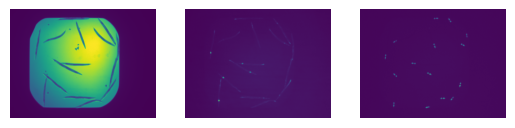

[Brightfield] Dynamic range = (102.0, 4042.0)
[GFP] Dynamic range = (147.0, 882.0)
[mCherry] Dynamic range = (104.0, 748.0)
float64


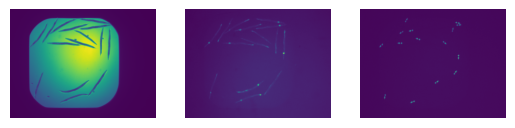

[Brightfield] Dynamic range = (100.0, 3947.0)
[GFP] Dynamic range = (147.0, 1478.0)
[mCherry] Dynamic range = (102.0, 759.0)
float64


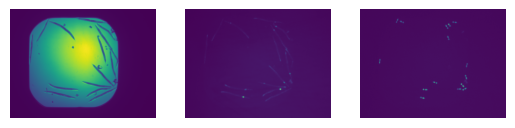

[Brightfield] Dynamic range = (105.0, 4095.0)
[GFP] Dynamic range = (148.0, 1300.0)
[mCherry] Dynamic range = (105.0, 810.0)
float64


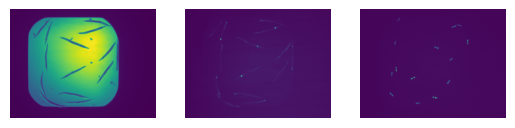

[Brightfield] Dynamic range = (102.0, 4095.0)
[GFP] Dynamic range = (147.0, 1655.0)
[mCherry] Dynamic range = (105.0, 837.0)
float64


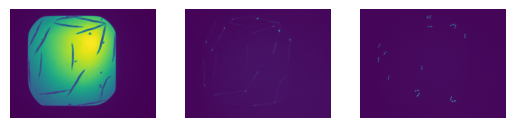

[Brightfield] Dynamic range = (102.0, 4095.0)
[GFP] Dynamic range = (151.0, 1716.0)
[mCherry] Dynamic range = (103.0, 1052.0)
float64


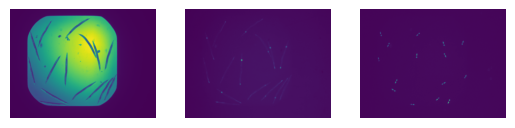

[Brightfield] Dynamic range = (104.0, 4095.0)
[GFP] Dynamic range = (149.0, 1468.0)
[mCherry] Dynamic range = (103.0, 1052.0)
float64


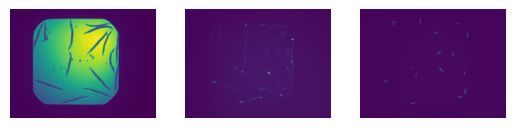

[Brightfield] Dynamic range = (104.0, 4095.0)
[GFP] Dynamic range = (146.0, 1250.0)
[mCherry] Dynamic range = (102.0, 947.0)
float64


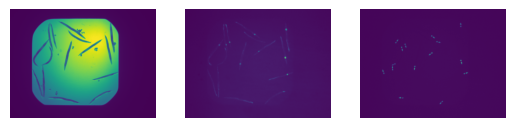

In [ ]:
path = "./dataset/"
images = read_files(path)
image_types = ["Brightfield", "GFP", "mCherry"]

for im in images:
    fig, ax = plt.subplots(1,3)
    for i in range(3):
        ax[i].axis('off')
        ax[i].imshow(im[:,:,i])
        print(f"[{image_types[i]}] Dynamic range = ({np.min(im[:,:,i])}, {np.max(im[:,:,i])})")
    print(im.dtype)
    plt.show()
    print("="*80)
    


### 1. Normalización del Rango Dinámico

Al tratarse de  imágenes de 16 bits, cargadas con la librería tifffile, es necesario su posterior normalización de rango dinámico para el procesamiento y poder aplicar los algoritmos de segmentación. Se aplicó por lo tanto una normalización Min-Max que reescala las intensidades al rango [0-255], convirtiendo los datos a enteros de 8 bits (uint8) para eliminar los decimales resultantes y asegurar la estricta compatibilidad con las funciones de OpenCV de los siguientes pasos.

Este proceso de reescalado se ejecutó de forma local (imagen por imagen) y de manera independiente para cada canal por dos motivos:
- Una normalización conjunta haría que el canal más brillante (Brightfield) comprimiera el rango dinámico de los demás, provocando una atenuación de las señales de los genes (GFP) y la faringe (mCherry) que resultaría en su pérdida al aplicar la umbralización posterior.
- Al maximizar el contraste de cada imagen de forma independiente, se garantiza que los algoritmos de umbralización detecten las estructuras (gusanos, genes, faringes) de manera estable en todas las muestras, independientemente de si algunas fotos se capturaron más oscuras que otras en el laboratorio.






In [6]:
# 1. Normalización Min-Max independiente por canal
imagenes_norm = [] 

for im in images:
    # Creamos una imagen vacía de 8 bits (uint8) para guardar los canales procesados
    im_norm = np.zeros_like(im, dtype='uint8')
    
    # --- Canal w1 (Brightfield - Muestra la morfología de los gusanos) ---
    w1 = im[:,:,0].astype(float)
    im_norm[:,:,0] = ((w1 - w1.min()) / (w1.max() - w1.min()) * 255).astype('uint8')
    
    # --- Canal w2 (GFP - Focos de activación de genes) ---
    w2 = im[:,:,1].astype(float)
    im_norm[:,:,1] = ((w2 - w2.min()) / (w2.max() - w2.min()) * 255).astype('uint8')
    
    # --- Canal w3 (mCherry - Localización de la faringe) ---
    w3 = im[:,:,2].astype(float)
    im_norm[:,:,2] = ((w3 - w3.min()) / (w3.max() - w3.min()) * 255).astype('uint8')
    
    imagenes_norm.append(im_norm)

# Verificación de rangos por canal utilizando la primera imagen
for i, nombre in enumerate(["Brightfield", "GFP", "mCherry"]):
    canal_data = imagenes_norm[0][:,:,i]
    print(f"Canal {nombre} (w{i+1}) -> Rango: {canal_data.min()} a {canal_data.max()}")

Canal Brightfield (w1) -> Rango: 0 a 255
Canal GFP (w2) -> Rango: 0 a 255
Canal mCherry (w3) -> Rango: 0 a 255


### 2. Segmentación de individuos
Para la segmentación automática de los individuos se utiliza el canal w1 (Brightfield) de campo claro, que captura la morfología de los nematodos.
Como el campo claro ofrece iluminación de fondo irregular, se han descartado los métodos de umbralización global.

El flujo del procesamiento consiste en los siguientes pasos:
1. **Filtro de Mediana:** 

    Suavizado con filtro de mediana (no desenfoca los bordes de los gusanos a diferencia del gaussiano) para reducir los artefactos digitales (píxeles oscuros/brillantes erróneamente). Se aplica a modo preventivo para que las operaciones morfológicas posteriores (blackhat y umbralización local) no los detecten.

2. **Transformación Black-Hat:** 

    Operación morfológica que extrae estructuras oscuras sobre un fondo claro. Para que funcione correctamente, se definió un kernel elíptico de 61x61 píxeles. Este tamaño es intencionalmente superior al ancho de los gusanos para que el algoritmo black-hat considere que cualquier mancha oscura más estrecha que 61 píxeles es una estructura de interés y la separe, ignorando variaciones generales de luz del fondo.

    Se aplica posteriormente una normalización Min-Max necesaria previamente a la umbralización, ya que black-hat genera una imagen resultado en escala de grises. Se normaliza al rango [0-255] para poder aplicar la umbralización que viene a continuación y operaciones posteriores. 

3. **Umbralización Adaptativa Gaussiana:** 

    Como los nematodos extraídos presentan diferencias en la densidad de sus cuerpos (visible tras el black-hat; algunas regiones internas aparecen más brillantes y otras más translúcidas u oscuras), una umbralización global haría que sus cuerpos se fragmentaran. La umbralización adaptativa resuelve el problema, calculando un umbral de corte independiente y dinámico para cada píxel, basándose exclusivamente en la intensidad de los píxeles de su entorno inmediato.

    Se aplica el método gaussiano, que otorga mayor importancia a los píxeles cercanos al centro, generando bordes precisos. 

4. **Apertura Morfológica:** 
    
    Erosión seguida de dilatación (kernel 3x3) para eliminar ruido residual, motas blancas y separar individuos que se tocan.

5. **Identificación de individuos y estructuración de datos:** 

    Primero, la función connectedComponentsWithStats escanea la máscara binaria. Identifica el número de objetos totales (num_labels), asigna una etiqueta con el número del objeto al que pertenecen a cada píxel y precalcula las propiedades geométricas (stats) y los centroides de cada uno.

    A continuación, se evalúa cada objeto detectado de forma individual (omitiendo el 0 porque corresponde al fondo). Se aplica un filtro de área para descartar artefactos o motas residuales. Si el objeto supera este filtro, se genera su máscara binaria individual y se calculan sus bordes (cv2.findContours).

    Para gestionar esta información de cara a la asociación espacial final, se diseña una arquitectura de datos jerárquica en tres niveles:

    - Diccionario individual: Por cada gusano validado, se crea una estructura que almacena su identificador (id), su máscara binaria (mask), sus coordenadas numéricas (centro) y sus bordes (contorno).

    - Lista local (individuos_foto): Agrupa todos los diccionarios individuales correspondientes a una única imagen.

    - Lista global (resultados_por_imagen): Almacena las listas locales de todas las imágenes procesadas en el bucle. Esta matriz global es la variable definitiva que se exportará a la etapa final de asociación espacial.

    Para la validación visual de los resultados de esta etapa, se crea una lista auxiliar (lista_centroides_gusanos) encargada de registrar las coordenadas espaciales de los centroides de cada nematodo identificado por imagen. Asimismo, se representan los contornos previamente almacenados en el diccionario de cada individuo mediante la función cv2.drawContours, proyectándolos sobre un lienzo negro y asignando una codificación de color distinta a cada gusano para facilitar su discriminación.


--- IMAGEN 1 ---
Número de gusanos detectados: 13
Coordenadas de los individuos: [(464, 106), (337, 124), (443, 138), (131, 169), (215, 136), (515, 205), (492, 295), (291, 272), (218, 355), (472, 384), (164, 399), (331, 422), (377, 447)]


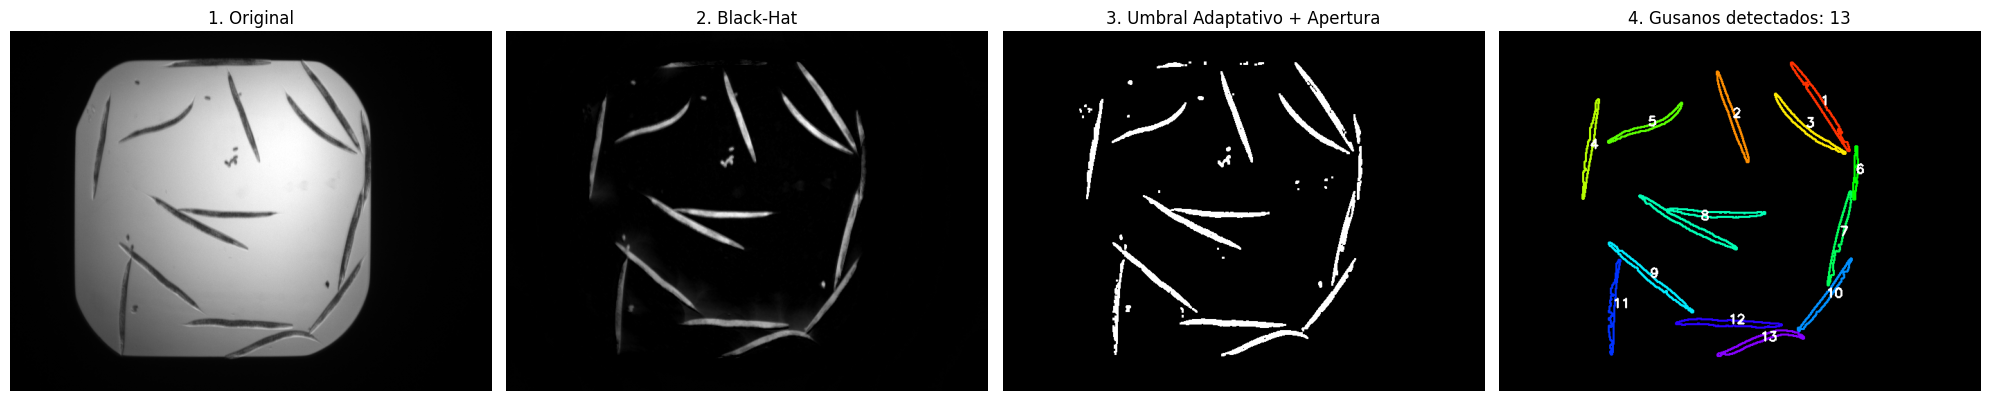


--- IMAGEN 2 ---
Número de gusanos detectados: 15
Coordenadas de los individuos: [(190, 105), (251, 79), (405, 58), (140, 130), (303, 90), (404, 86), (436, 153), (473, 169), (362, 131), (333, 161), (255, 165), (419, 351), (135, 360), (309, 378), (303, 421)]


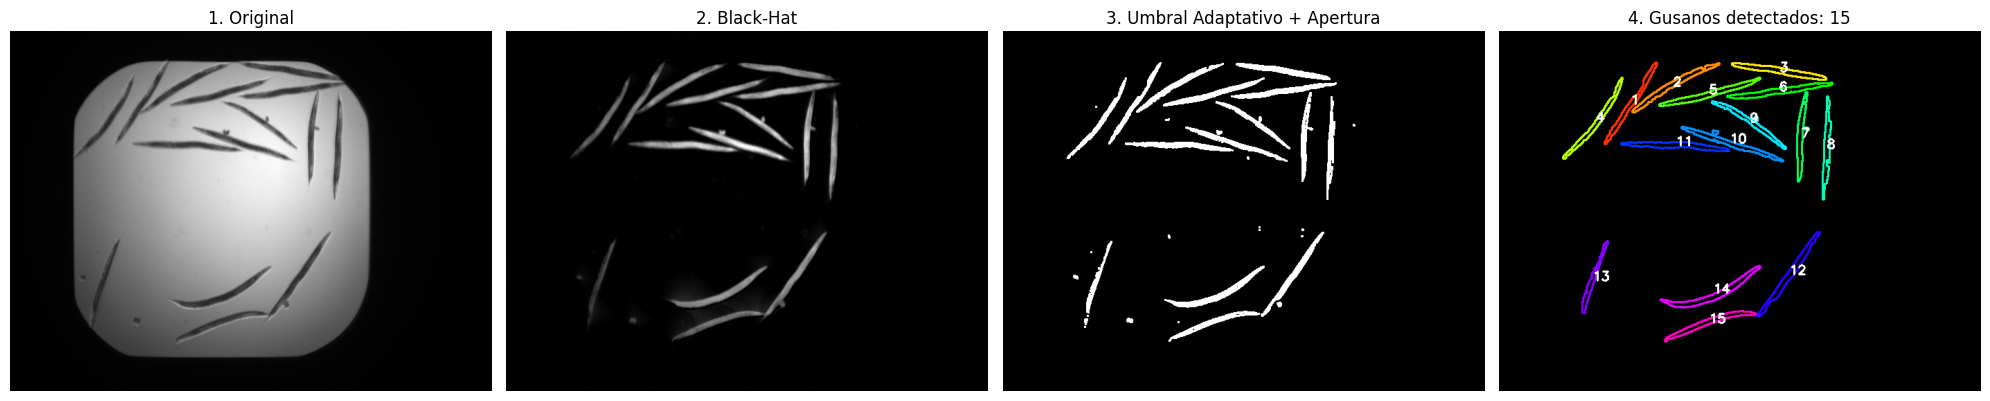


--- IMAGEN 3 ---
Número de gusanos detectados: 14
Coordenadas de los individuos: [(397, 57), (155, 104), (254, 94), (459, 104), (464, 166), (101, 187), (440, 193), (489, 265), (449, 321), (415, 362), (252, 376), (440, 407), (237, 406), (418, 392)]


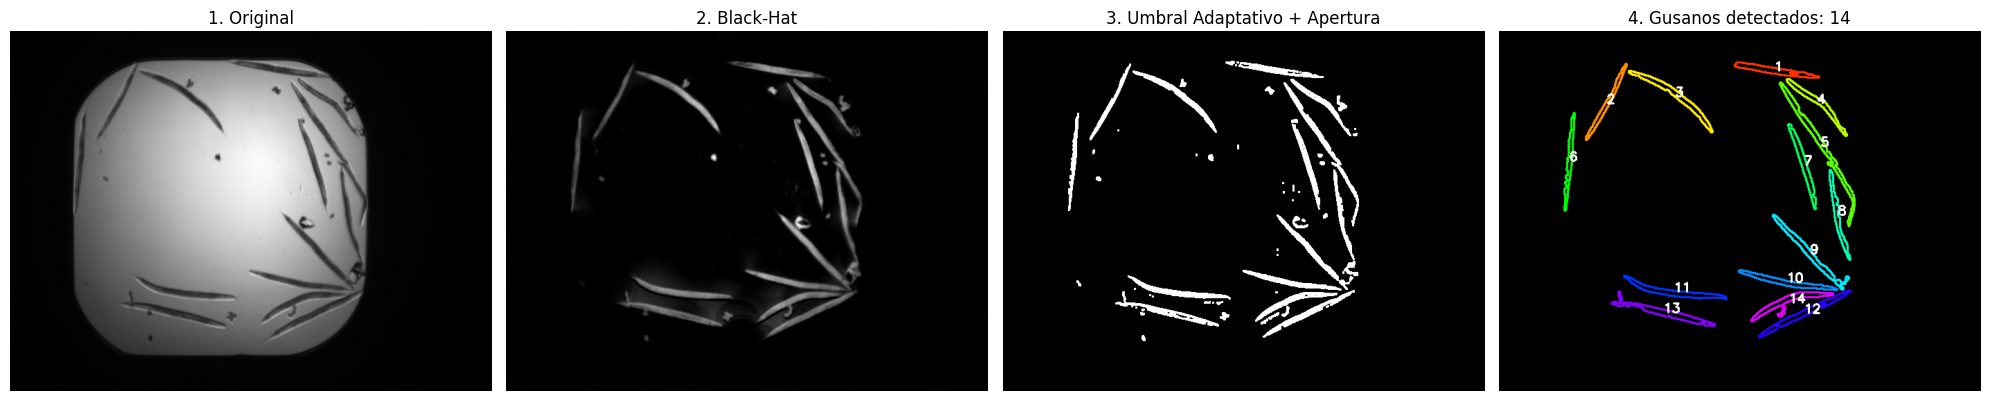


--- IMAGEN 4 ---
Número de gusanos detectados: 13
Coordenadas de los individuos: [(153, 90), (415, 63), (181, 113), (390, 103), (309, 162), (469, 202), (173, 230), (457, 297), (300, 303), (154, 357), (195, 440), (301, 408), (329, 443)]


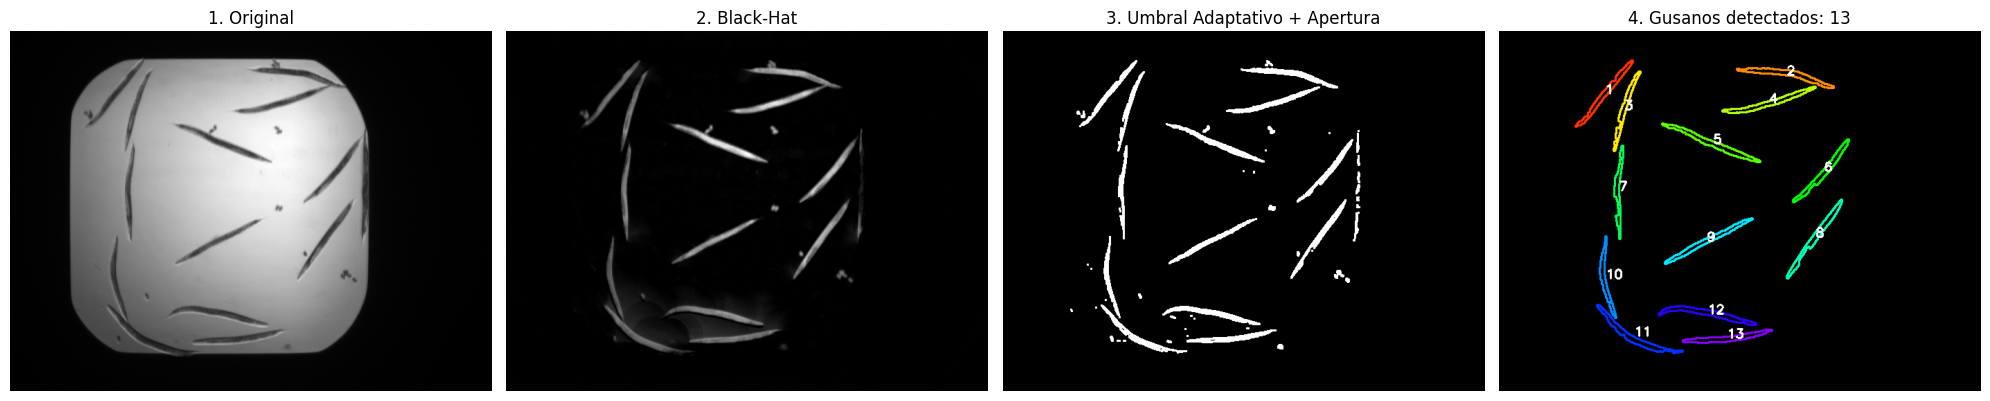


--- IMAGEN 5 ---
Número de gusanos detectados: 14
Coordenadas de los individuos: [(260, 43), (414, 102), (120, 119), (275, 78), (381, 97), (155, 152), (298, 221), (495, 212), (145, 272), (93, 323), (313, 352), (449, 371), (211, 398), (403, 447)]


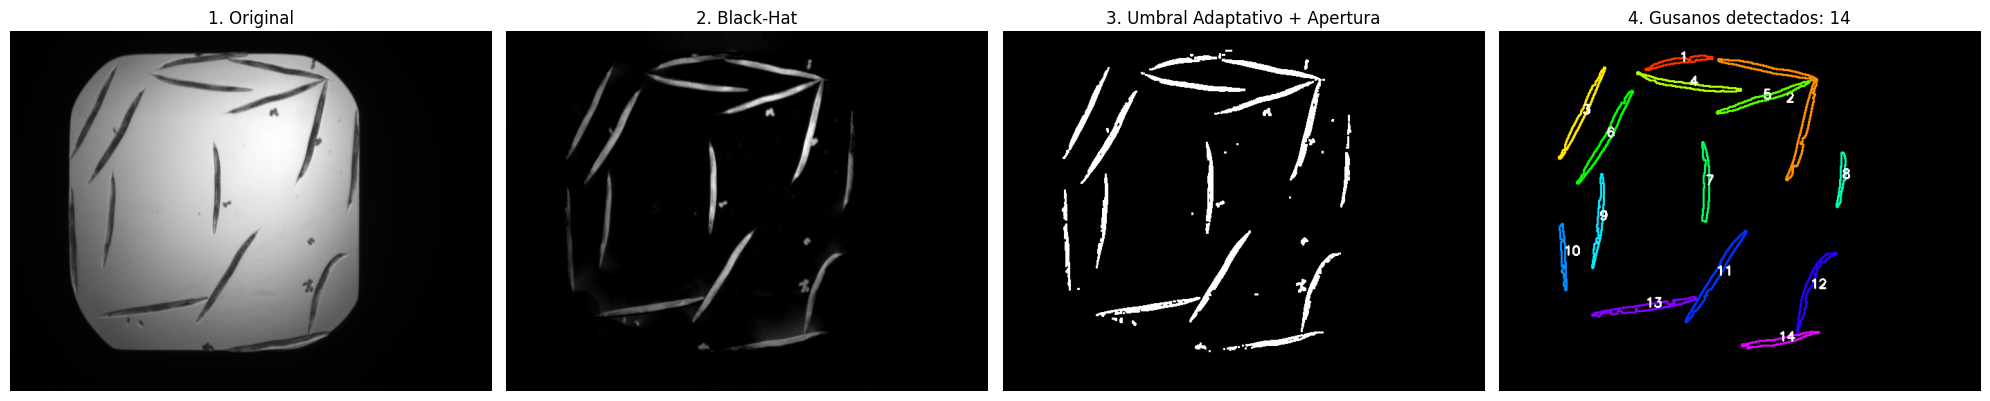


--- IMAGEN 6 ---
Número de gusanos detectados: 15
Coordenadas de los individuos: [(320, 84), (162, 116), (118, 178), (375, 167), (415, 218), (470, 221), (267, 286), (204, 282), (105, 301), (476, 376), (454, 381), (348, 387), (414, 384), (210, 416), (216, 451)]


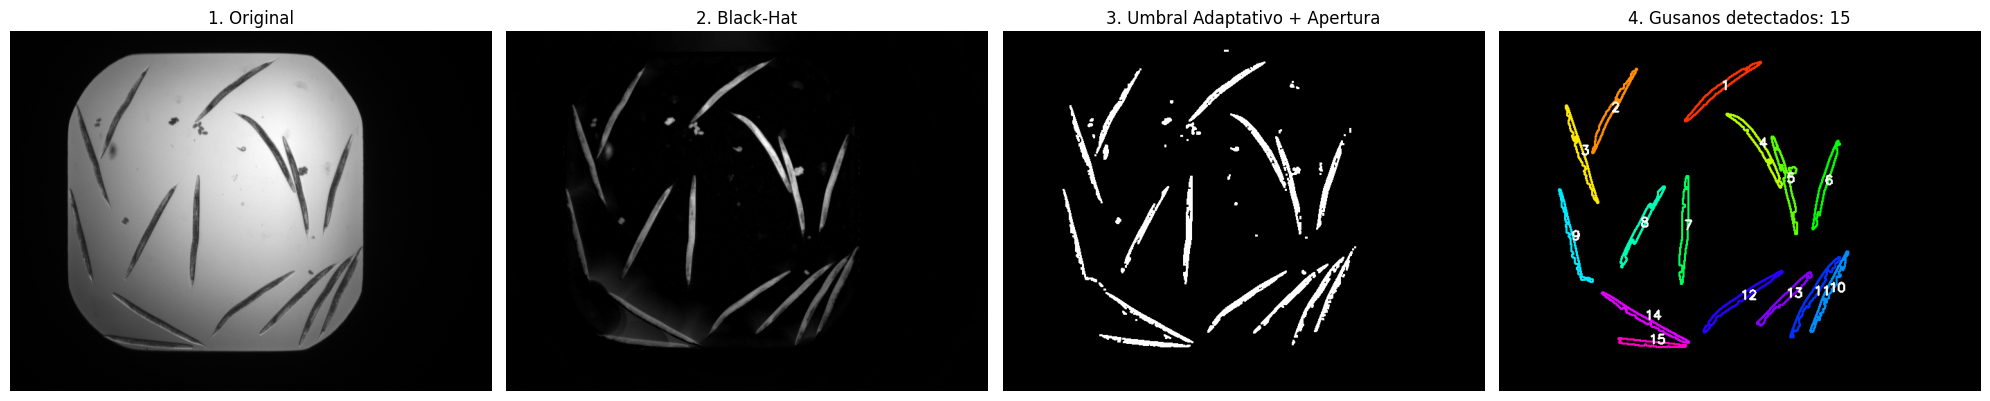


--- IMAGEN 7 ---
Número de gusanos detectados: 15
Coordenadas de los individuos: [(293, 122), (167, 106), (131, 129), (417, 76), (421, 95), (420, 160), (456, 163), (509, 216), (485, 247), (280, 267), (428, 335), (505, 339), (183, 362), (419, 397), (307, 432)]


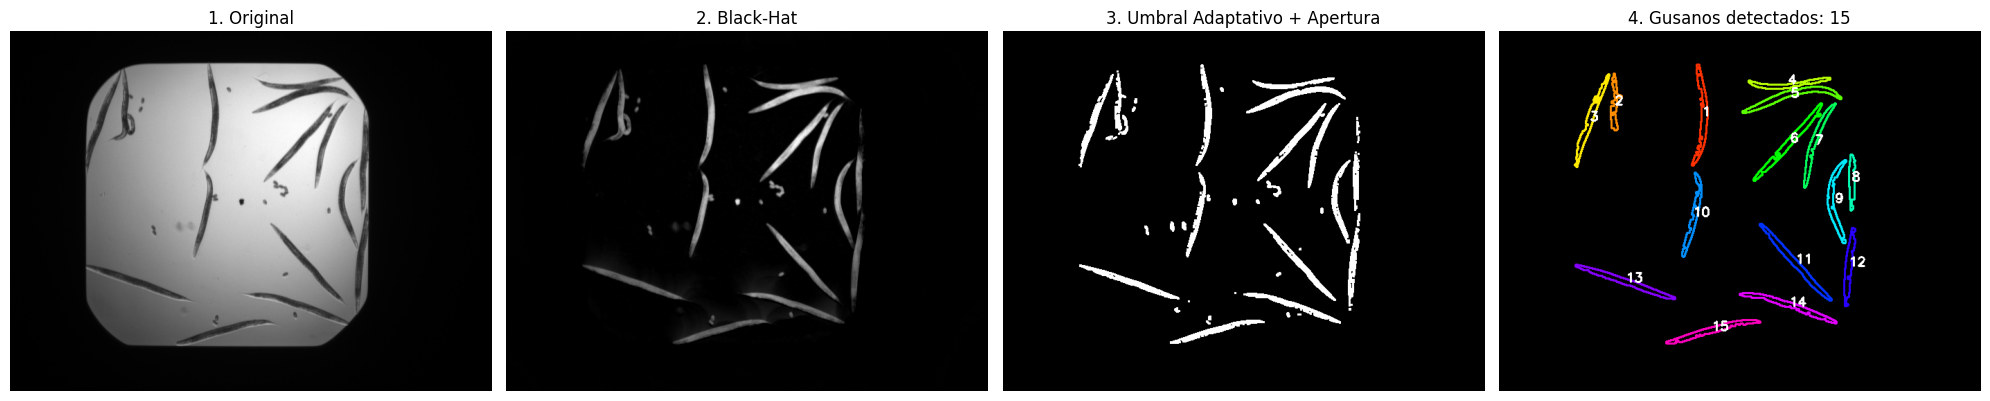


--- IMAGEN 8 ---
Número de gusanos detectados: 14
Coordenadas de los individuos: [(303, 99), (487, 138), (159, 177), (207, 129), (327, 139), (470, 192), (380, 185), (275, 220), (187, 232), (131, 347), (160, 355), (455, 320), (428, 414), (259, 431)]


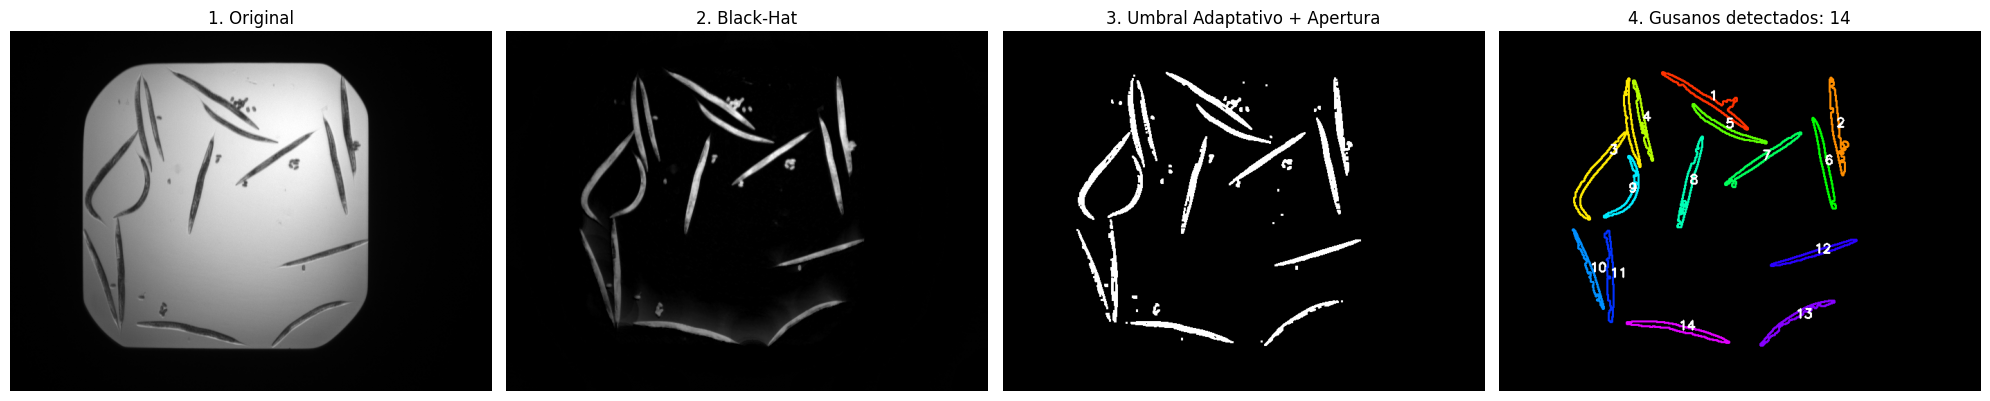

In [ ]:
# --- PARÁMETROS BÁSICOS -----
AREA_MINIMA = 300      
VALOR_C = -2           
KERNEL_BH = (61, 61)   

kernel_bh = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, KERNEL_BH) 
kernel_limpieza = np.ones((3,3), np.uint8) 

resultados_por_imagen = []

for idx, img_set in enumerate(imagenes_norm):
    img_original = img_set[:,:,0]
    
    # 1. FILTRO MEDIANO: Suavizado suave.
    img_clean = cv2.medianBlur(img_original, 3)
    
    # 2. BLACK-HAT: para resaltar los gusanos sobre el fondo
    img_bh = cv2.morphologyEx(img_clean, cv2.MORPH_BLACKHAT, kernel_bh)
    img_bh_8u = cv2.normalize(img_bh, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    
    # 3. UMBRAL ADAPTATIVO
    mask_bin = cv2.adaptiveThreshold(img_bh_8u, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
                                     cv2.THRESH_BINARY, 15, VALOR_C)
    
    # 4. Apertura (Open)
    mask_bin = cv2.morphologyEx(mask_bin, cv2.MORPH_OPEN, kernel_limpieza)
    
    # 5. Identificar individuos
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask_bin)
    
    # Inicialización estructuras
    individuos_foto = []
    lista_centroides_gusanos = [] # lista auxiliar para la validación visual
    
    h, w = mask_bin.shape 
    vis_multicolor = np.zeros((h, w, 3), dtype=np.uint8) 
    cmap = plt.get_cmap('gist_rainbow') 
    
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        
        if area > AREA_MINIMA:
            mask_ind = (labels == i).astype(np.uint8) * 255 
            cnts, _ = cv2.findContours(mask_ind, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) 
            
            # Centroide
            cx = int(round(centroids[i][0]))
            cy = int(round(centroids[i][1]))
            centro_limpio = (cx, cy)
            
            lista_centroides_gusanos.append(centro_limpio)
            
            # Lista local
            individuos_foto.append({
                "id": len(individuos_foto) + 1,
                "mask": mask_ind, 
                "centro": centro_limpio, # Guardamos centroide con números enteros
                "contorno": cnts
            })
            
            # Dibujo de contorno para el control visual
            color_rgb = tuple(int(c * 255) for c in cmap(len(individuos_foto) / 15)[:3])
            cv2.drawContours(vis_multicolor, cnts, -1, color_rgb, 2)
            cv2.putText(vis_multicolor, str(len(individuos_foto)), (cx, cy), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

    resultados_por_imagen.append(individuos_foto)

    # --- IMPRESIÓN DE RESULTADOS POR IMAGEN ---
    print(f"\n--- IMAGEN {idx + 1} ---")
    print(f"Número de gusanos detectados: {len(individuos_foto)}")
    print(f"Coordenadas de los individuos: {lista_centroides_gusanos}")

    # --- Visualización --- 
    plt.figure(figsize=(20, 5))
    
    plt.subplot(1, 4, 1)
    plt.imshow(img_original, cmap='gray')
    plt.title("1. Original")
    plt.axis('off')
    
    plt.subplot(1, 4, 2)
    plt.imshow(img_bh_8u, cmap='gray')
    plt.title("2. Black-Hat")
    plt.axis('off')
    
    plt.subplot(1, 4, 3)
    plt.imshow(mask_bin, cmap='gray')
    plt.title("3. Umbral Adaptativo + Apertura")
    plt.axis('off')
    
    plt.subplot(1, 4, 4)
    plt.imshow(vis_multicolor)
    plt.title(f"4. Gusanos detectados: {len(individuos_foto)}")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

### 3. Identificación de la expresión de los genes

- Segmentación por Umbralización Global (Umbral = 48)

     Se optó por una umbralización global binaria ya que, a diferencia del campo claro, el canal w2 (GFP) presenta un fondo negro uniforme y limpio, lo que permite la aplicación de una umbralización global binaria (cv2.threshold), estableciendo un punto de corte único. El valor del umbral se ajustó a 48 porque se encontró que es el valor que permite discriminar los focos de activación reales frente a la autofluorescencia basal del cuerpo del nematodo, la cual se ve amplificada durante la normalización.

- Extracción de Centroides

    Para la localización espacial de los genes, se utilizó la función connectedComponentsWithStats, que identifica cada objeto y calcula automáticamente su centro de masa. Creamos para almacenar los resultados dos estructuras: 
    
    - Lista local (centroides_esta_imagen): Almacena las coordenadas de cada gen detectado en una imagen específica. Se aplica un redondeo a números enteros (int(round())) para que estas coordenadas correspondan a píxeles exactos. Esto es necesario para la última fase del proceso, para asociar cada gen detectado al nematodo que lo contiene, a través de validar si cae dentro de su máscara binaria.

    - Lista global (lista_centroides_global): contiene las listas de centroides de todo el set de imágenes. Se utilizará en la última etapa del proceso, para la asociación nematodo-gen-faringe.
    


--- Imagen 1 ---
Número de genes detectados: 15
Coordenadas de los centroides: [(500, 163), (122, 208), (512, 240), (274, 260), (373, 264), (311, 301), (182, 327), (502, 343), (170, 340), (169, 344), (497, 353), (167, 363), (450, 411), (161, 436), (429, 439)]


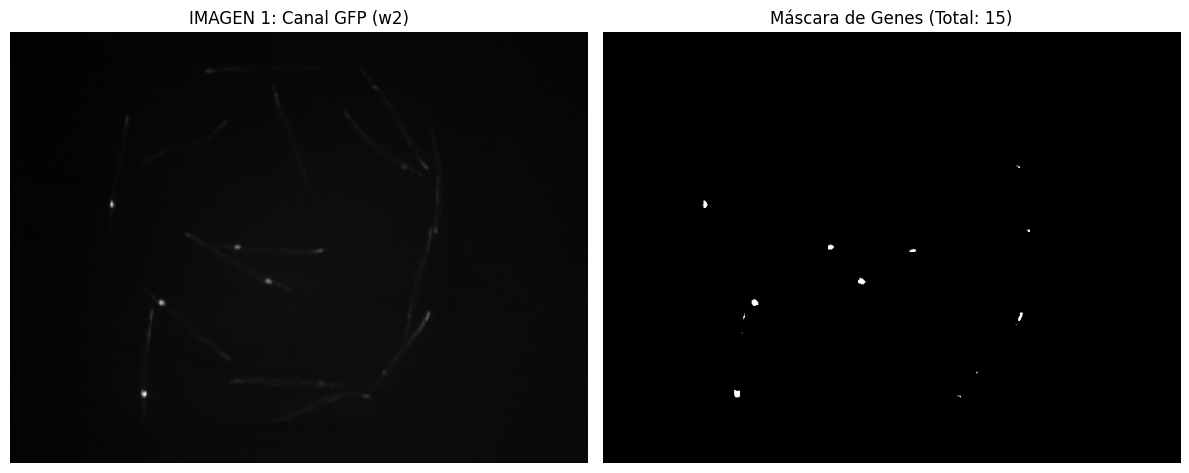


--- Imagen 2 ---
Número de genes detectados: 38
Coordenadas de los centroides: [(297, 53), (445, 62), (214, 68), (359, 73), (173, 76), (451, 78), (342, 93), (344, 92), (263, 99), (211, 100), (475, 115), (322, 105), (159, 150), (471, 152), (114, 161), (471, 159), (212, 163), (471, 164), (322, 171), (432, 182), (392, 180), (433, 206), (470, 210), (151, 313), (449, 309), (442, 318), (348, 361), (408, 363), (406, 368), (402, 373), (292, 388), (265, 395), (382, 402), (122, 399), (357, 409), (327, 412), (322, 416), (267, 435)]


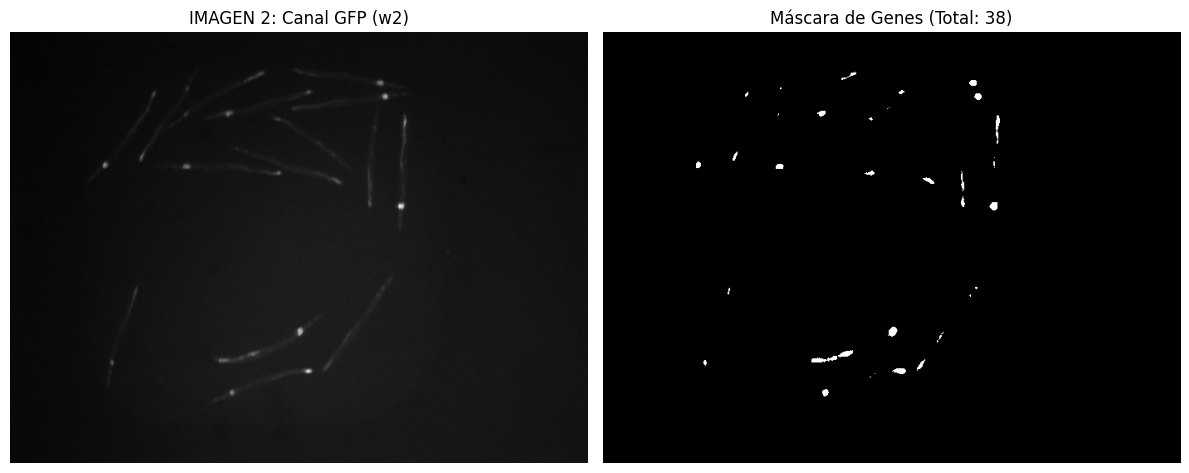


--- Imagen 3 ---
Número de genes detectados: 15
Coordenadas de los centroides: [(434, 83), (424, 100), (482, 193), (485, 196), (480, 210), (455, 245), (500, 308), (473, 350), (378, 354), (194, 363), (475, 372), (454, 382), (289, 384), (375, 410), (277, 419)]


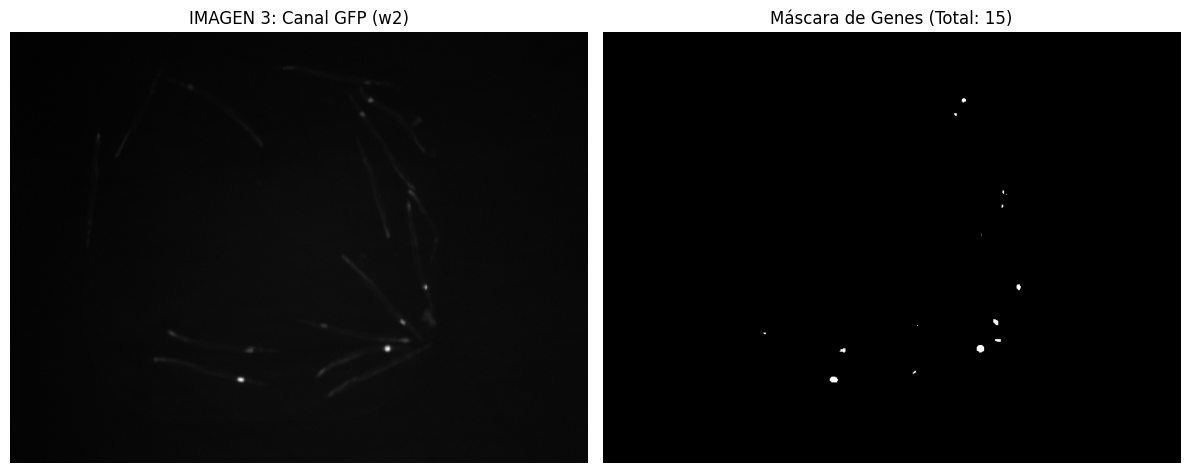


--- Imagen 4 ---
Número de genes detectados: 14
Coordenadas de los centroides: [(361, 55), (198, 64), (430, 90), (170, 143), (346, 178), (512, 177), (486, 188), (445, 228), (510, 285), (269, 319), (150, 326), (163, 404), (239, 405), (378, 436)]


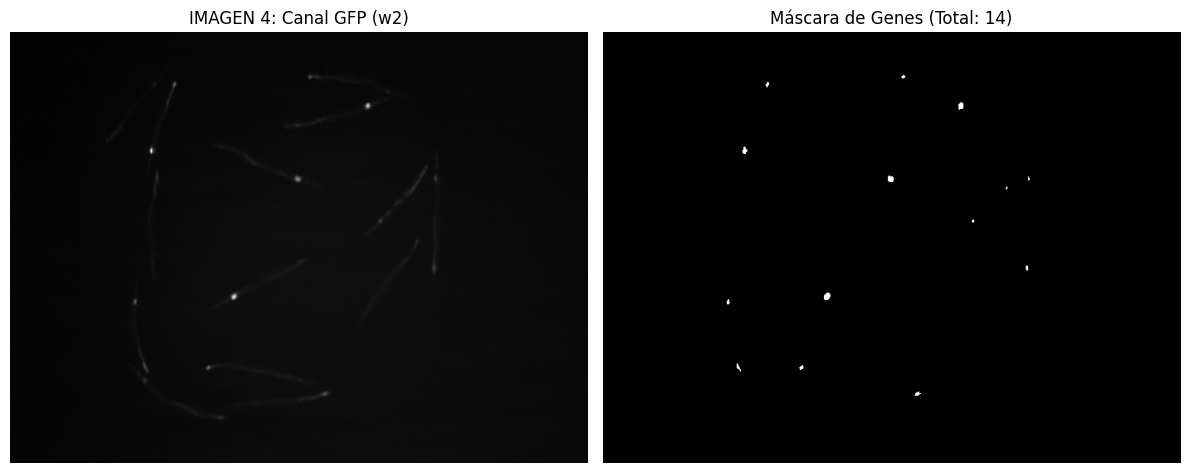


--- Imagen 5 ---
Número de genes detectados: 14
Coordenadas de los centroides: [(346, 45), (228, 48), (422, 82), (188, 91), (449, 103), (501, 146), (101, 157), (429, 182), (128, 195), (94, 365), (288, 391), (146, 408), (428, 442), (331, 459)]


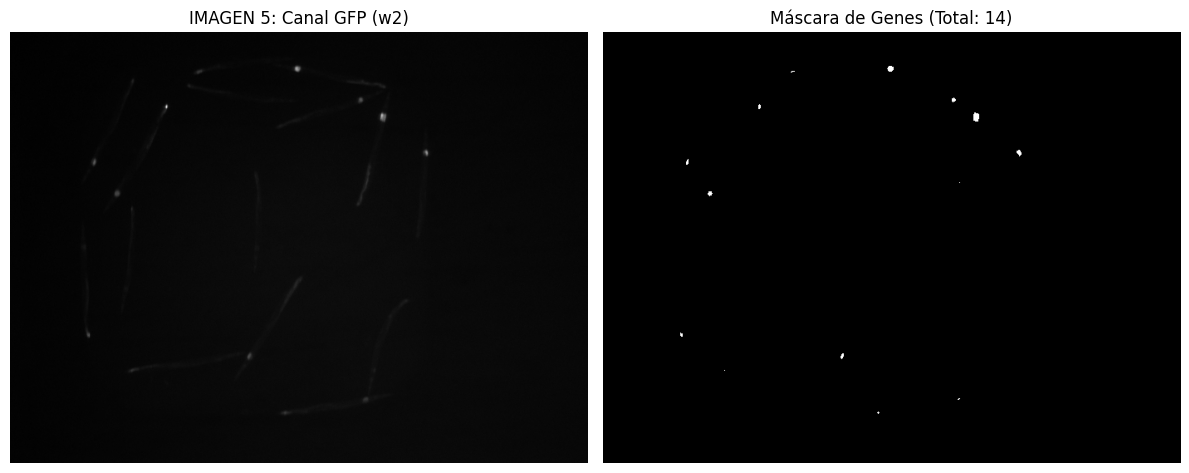


--- Imagen 6 ---
Número de genes detectados: 16
Coordenadas de los centroides: [(192, 61), (290, 109), (103, 138), (483, 179), (406, 184), (396, 204), (270, 243), (427, 279), (455, 280), (462, 342), (114, 348), (263, 358), (175, 397), (383, 415), (430, 423), (152, 443)]


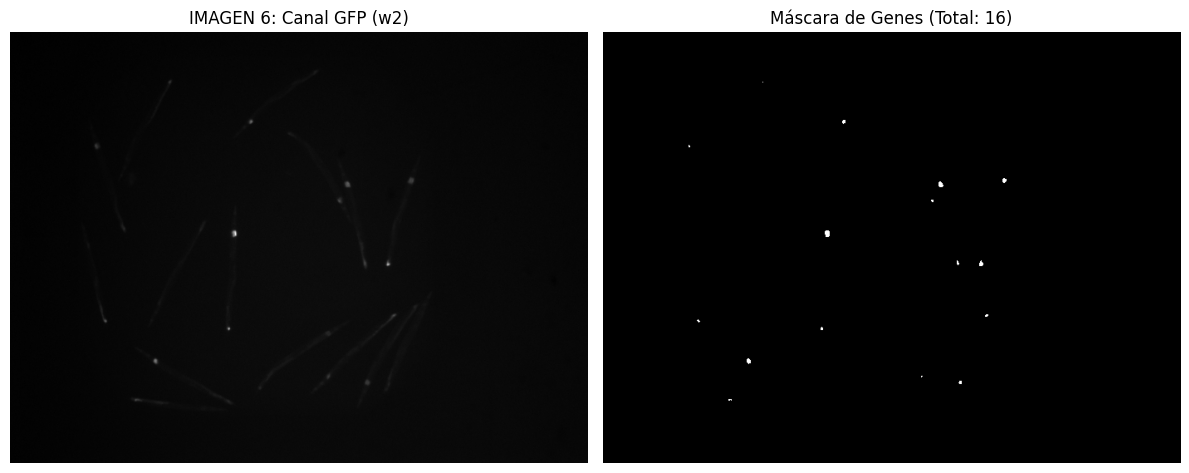


--- Imagen 7 ---
Número de genes detectados: 20
Coordenadas de los centroides: [(290, 77), (369, 76), (513, 145), (282, 186), (494, 194), (447, 198), (509, 250), (515, 267), (490, 286), (243, 288), (273, 299), (399, 304), (139, 348), (363, 381), (244, 384), (456, 411), (361, 421), (335, 426), (330, 428), (269, 443)]


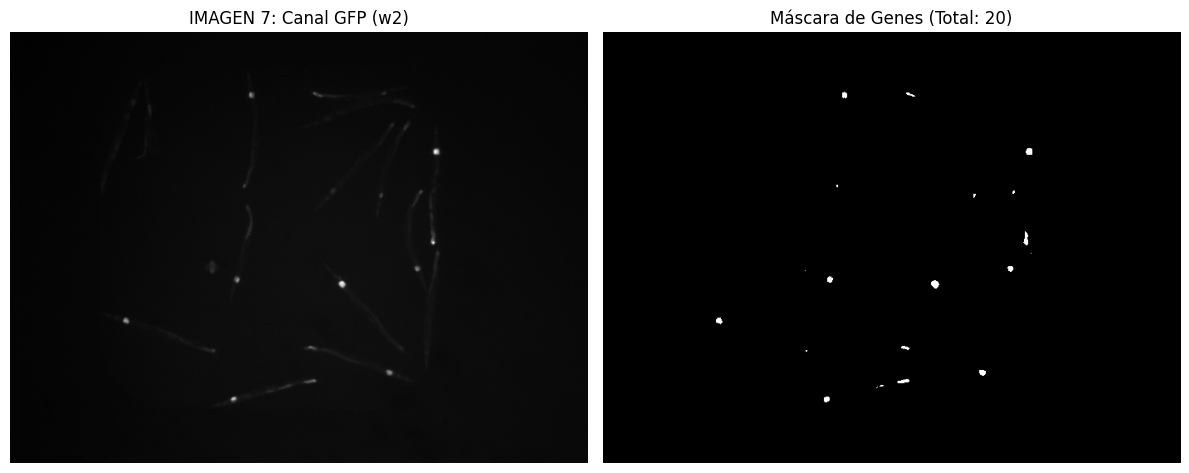


--- Imagen 8 ---
Número de genes detectados: 16
Coordenadas de los centroides: [(196, 77), (482, 97), (332, 121), (213, 158), (196, 170), (164, 171), (191, 187), (494, 192), (193, 192), (352, 201), (478, 231), (263, 261), (487, 312), (404, 335), (471, 393), (320, 446)]


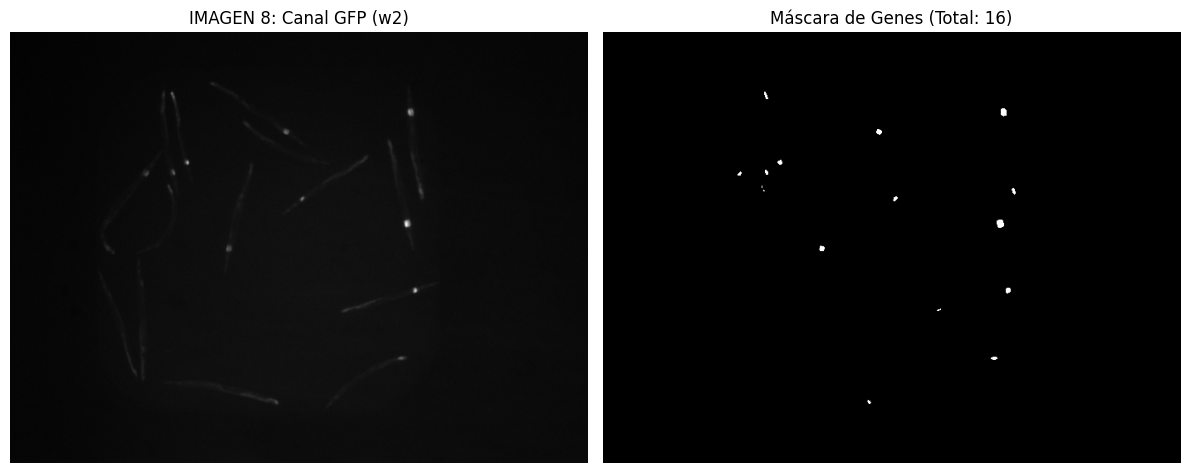

In [ ]:
# --- PARÁMETROS ---
UMBRAL_GFP = 48  # Umbral de intensidad

# Lista con los centroides de cada imagen
lista_centroides_global = []

for idx, img_set in enumerate(imagenes_norm):
    
    # Seleccionamos el canal w2 (GFP / Genes)
    img_w2 = img_set[:,:,1] 
    
    # Umbralización binaria global
    _, mask = cv2.threshold(img_w2, UMBRAL_GFP, 255, cv2.THRESH_BINARY)
    
    # Centroides
    n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask)
    
    centroides_esta_imagen = []
    
    # Empezamos en 1 para saltar el fondo (label 0)
    for i in range(1, n):
        # Convertimos las coordenadas a enteros redondeados directamente
        cx = int(round(centroids[i][0]))
        cy = int(round(centroids[i][1]))
        centroides_esta_imagen.append((cx, cy))
    
    # Guardamos los resultados en la lista global
    lista_centroides_global.append(centroides_esta_imagen)

    # --- IMPRESIÓN DE RESULTADOS ---
    print(f"\n--- Imagen {idx + 1} ---")
    print(f"Número de genes detectados: {len(centroides_esta_imagen)}")
    print(f"Coordenadas de los centroides: {centroides_esta_imagen}")

    # --- VISUALIZACIÓN ---
    plt.figure(figsize=(12, 5))
    
    # Izquierda: Imagen original del canal (w2)
    plt.subplot(1, 2, 1)
    plt.imshow(img_w2, cmap='gray')
    plt.title(f"IMAGEN {idx + 1}: Canal GFP (w2)")
    plt.axis('off')
    
    # Derecha: Máscara resultante (sin filtros de área)
    plt.subplot(1, 2, 2)
    plt.imshow(mask, cmap='gray')
    plt.title(f"Máscara de Genes (Total: {len(centroides_esta_imagen)})")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

### 4. Extracción de la faringe
En el procesamiento del canal w3 (mCherry) para identificar las faringes, los pasos han sido los siguientes:

1. Umbralización binaria global: Se opta por este método en lugar de uno adaptativo porque el fondo de las imágenes es uniforme y negro. Al no haber variaciones de iluminación complejas en el fondo, un corte limpio en 40 es suficiente para aislar los píxeles de la faringe.

2. Dilatación morfológica: Se han expandido los píxeles blancos de la máscara utilizando un kernel circular. Como la binarización detecta los dos 'lóbulos' de la faringe, se ha aplicado la dilatación para que las manchas crezcan hasta tocarse y se cuenten como una única, en lugar de erróneamente dos.
La desventaja de este método es que faringes distintas muy próximas se contarán como una sola pero no se han encontrado otros procesos que logren obtener mejores resultados .

3. Extracción de los centroides y estructura de datos: Se utiliza la función connectedComponentsWithStats, que identifica los objetos independientes en la máscara fusionada y se calcula su centroide. El proceso genera dos estructuras de datos jerárquicas:
- Lista local (faringes_esta_imagen): Almacena las coordenadas (redondeadas a enteros) de cada faringe detectada en la imagen actual.
- Lista global (lista_faringes_global): integra las coordenadas de todas las faringes del experimento, permitiendo su recuperación en la fase final de asociación multicanal.


--- Imagen 1 ---
Número de faringes detectadas: 15
Coordenadas de los centroides: [(363, 45), (429, 54), (510, 127), (167, 155), (356, 175), (490, 171), (122, 227), (256, 259), (331, 309), (168, 315), (478, 361), (440, 427), (395, 426), (162, 455), (322, 468)]


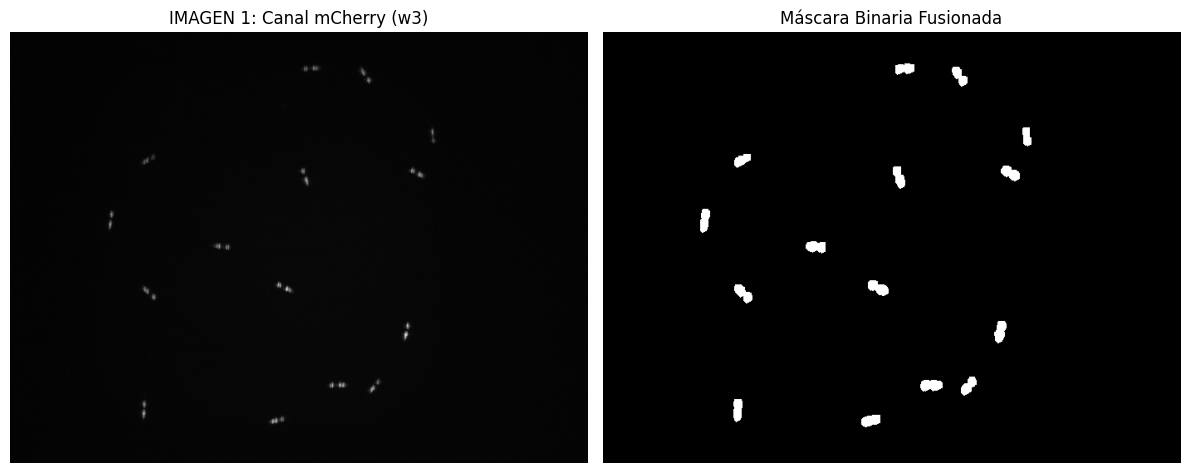


--- Imagen 2 ---
Número de faringes detectadas: 14
Coordenadas de los centroides: [(222, 53), (468, 71), (443, 99), (244, 103), (198, 112), (278, 143), (404, 161), (192, 163), (102, 174), (470, 228), (454, 303), (366, 349), (119, 417), (251, 443)]


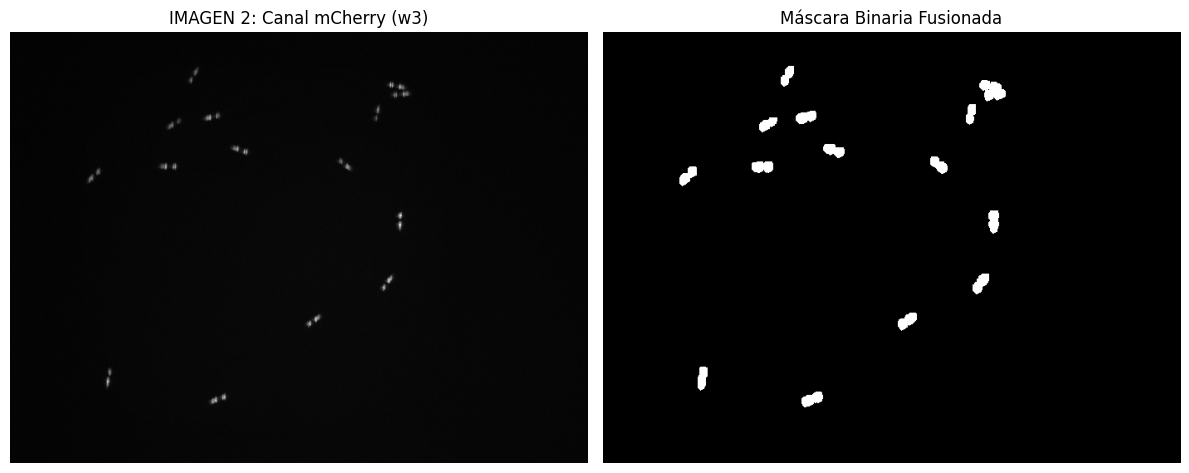


--- Imagen 3 ---
Número de faringes detectadas: 12
Coordenadas de los centroides: [(178, 56), (200, 61), (451, 63), (420, 81), (422, 138), (95, 249), (510, 268), (506, 325), (359, 351), (488, 375), (311, 384), (298, 424)]


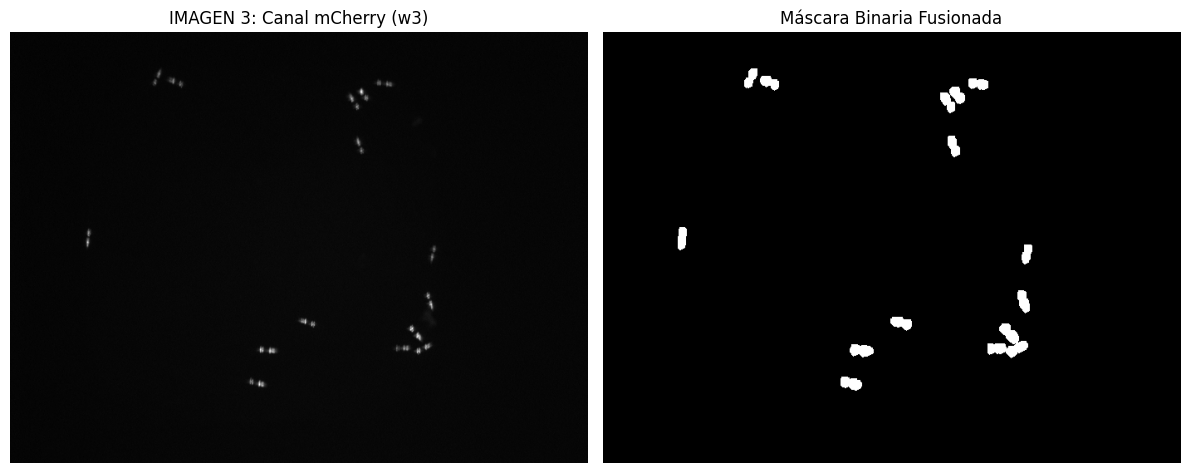


--- Imagen 4 ---
Número de faringes detectadas: 14
Coordenadas de los centroides: [(184, 51), (474, 78), (448, 84), (514, 157), (168, 162), (365, 184), (435, 240), (173, 287), (152, 310), (252, 329), (423, 348), (151, 408), (357, 422), (277, 449)]


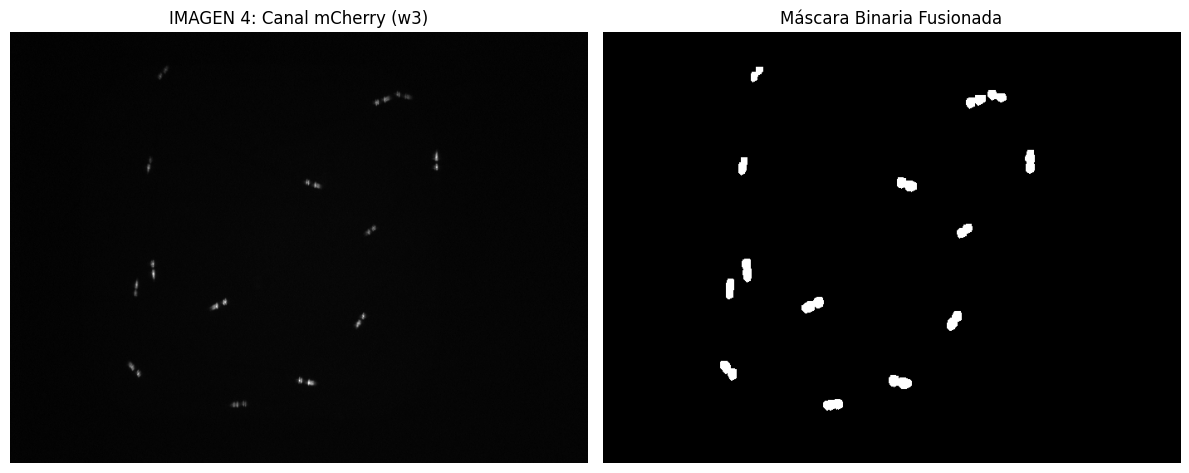


--- Imagen 5 ---
Número de faringes detectadas: 12
Coordenadas de los centroides: [(329, 39), (447, 80), (335, 84), (501, 128), (92, 175), (120, 209), (88, 241), (296, 280), (136, 328), (272, 389), (278, 409), (442, 433)]


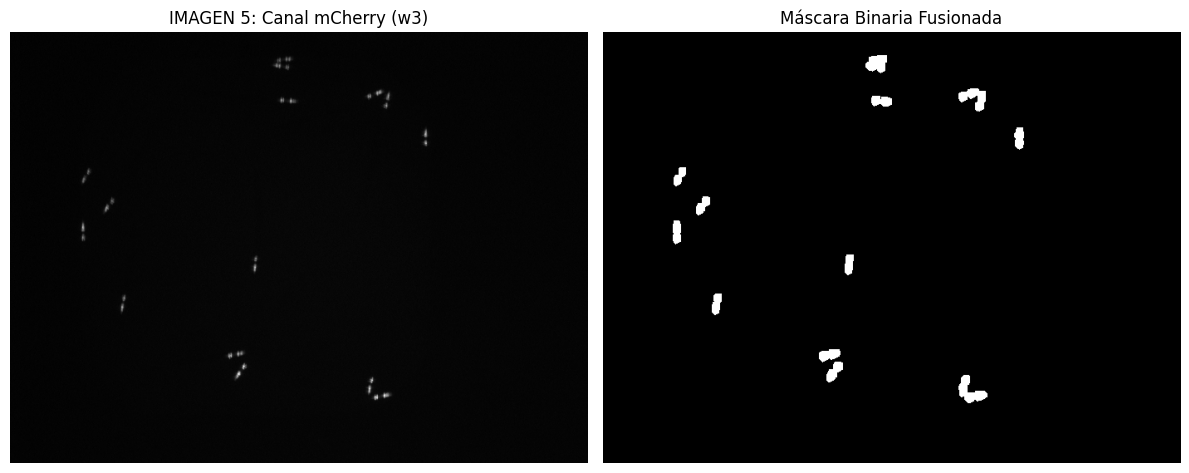


--- Imagen 6 ---
Número de faringes detectadas: 15
Coordenadas de los centroides: [(100, 120), (278, 121), (490, 161), (399, 166), (136, 170), (406, 220), (271, 223), (90, 240), (503, 322), (173, 345), (399, 355), (161, 387), (371, 429), (424, 441), (251, 455)]


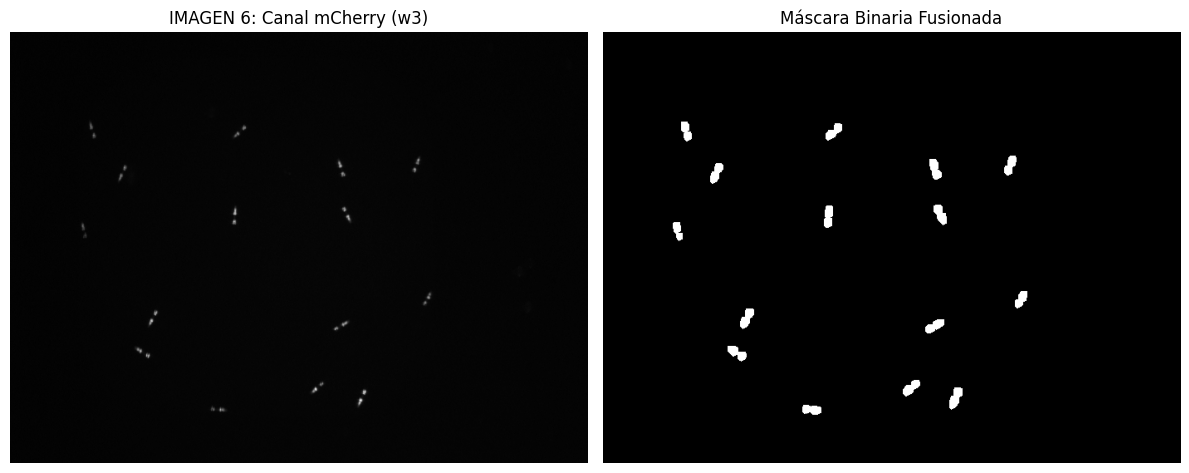


--- Imagen 7 ---
Número de faringes detectadas: 14
Coordenadas de los centroides: [(289, 59), (160, 68), (469, 70), (363, 113), (513, 125), (377, 207), (444, 215), (387, 289), (498, 304), (268, 316), (123, 343), (502, 393), (476, 418), (254, 449)]


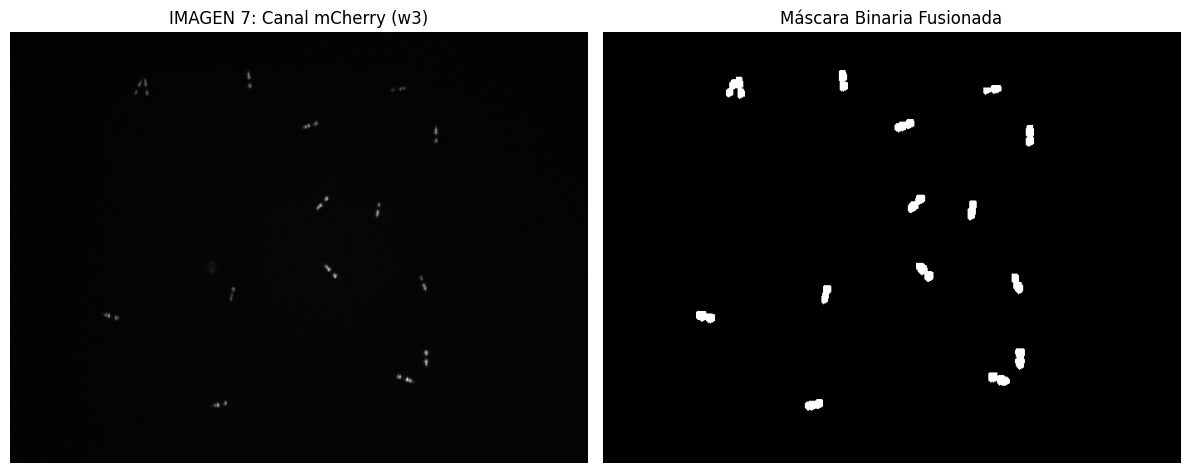


--- Imagen 8 ---
Número de faringes detectadas: 14
Coordenadas de los centroides: [(481, 76), (348, 133), (176, 154), (374, 158), (217, 174), (201, 189), (338, 213), (483, 252), (159, 274), (261, 281), (112, 300), (504, 306), (197, 424), (388, 446)]


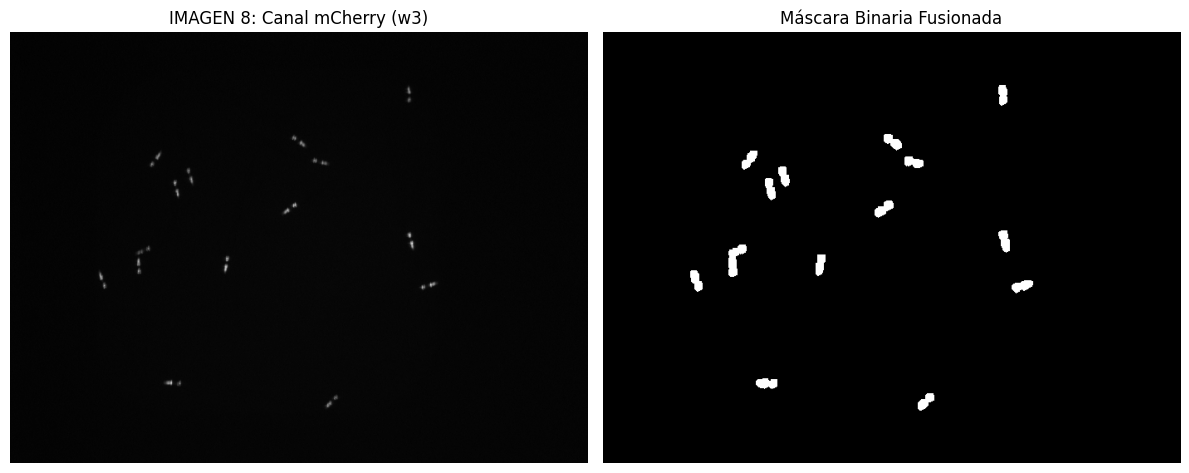

In [9]:
# --- PARÁMETROS PARA LA FARINGE (Canal w3) ---
UMBRAL_MCHERRY = 40      
TAMANO_CIRCULO = 4       
ITERACIONES = 2          

# Kernel circular para la unión de los lóbulos de la faringe
kernel_fusión = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TAMANO_CIRCULO, TAMANO_CIRCULO))

# Lista para guardar los centroides
lista_faringes_global = []

for idx, img_set in enumerate(imagenes_norm):
    
    # Canal w3 (mCherry)
    img_w3_raw = img_set[:,:,2] 
    img_w3_norm = img_w3_raw
    
    # 2. Umbralización binaria global
    _, mask_sep = cv2.threshold(img_w3_norm, UMBRAL_MCHERRY, 255, cv2.THRESH_BINARY)
    
    # 3. Dilatación para obtener una sola masa por faringe
    mask_faringe = cv2.dilate(mask_sep, kernel_fusión, iterations=ITERACIONES)
    
    # 4. Extracción de centroides
    n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask_faringe)
    
    faringes_esta_imagen = []
    
    for i in range(1, n):
        cx = int(round(centroids[i][0]))
        cy = int(round(centroids[i][1]))
        faringes_esta_imagen.append((cx, cy))
    
    # Guardamos los resultados en la lista global
    lista_faringes_global.append(faringes_esta_imagen)

    # --- IMPRESIÓN DE RESULTADOS POR IMAGEN ---
    print(f"\n--- Imagen {idx + 1} ---")
    print(f"Número de faringes detectadas: {len(faringes_esta_imagen)}")
    print(f"Coordenadas de los centroides: {faringes_esta_imagen}")

    # --- VISUALIZACIÓN DE LOS PASOS ---
    plt.figure(figsize=(12, 5))
    
    # Izquierda: La señal de entrada normalizada (w3)
    plt.subplot(1, 2, 1)
    plt.imshow(img_w3_norm, cmap='gray')
    plt.title(f"IMAGEN {idx +1}: Canal mCherry (w3)")
    plt.axis('off')
    
    # Derecha: El resultado de la segmentación (Máscara Final)
    plt.subplot(1, 2, 2)
    plt.imshow(mask_faringe, cmap='gray')
    plt.title(f"Máscara Binaria Fusionada")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

### 5. Relación espacial y localización

En esta etapa se integra la información extraída de los tres canales analizados previamente:

FASE 1
- Recuperación de los datos: Se han cargado las listas globales generadas en los pasos previos: resultado_por_imagen,  lista_centroides_global y listas_faringes_global. Se utiliza la imagen w1 normalizada como fondo para la representación.

- Lógica de Asociación: como la segmentación de individuos (PASO 2) ha sido en general exitosa, para determinar si un gen o una faringe pertenecen a un nematodo, se utiliza su máscara corporal binaria. Si el valor de la máscara en la coordenada del centroide es superior a 0, se confirma que la estructura se encuentra dentro de los límites físicos del individuo, procediendo a su asociación en la base de datos.

- Preparación para la visualización: la imagen de fondo se ha convertido a formato RGB para permitir el dibujo en color (vis_final). Sobre ella se dibujan contornos (Cian), IDs (Blanco), genes (Verde) y faringes (Rojo). Estas imágenes se almacenan en la lista imagenes_visualizacion.

- Estructuras de datos: La información se organiza de forma jerárquica para asegurar la trazabilidad:
    - asociacion_final: Lista global que almacena un diccionario por cada imagen procesada.

    - relacion_imagen: Diccionario que agrupa a los individuos de una misma imagen bajo la clave Individuo X.

    - Atributos de individuo: Diccionario anidado que contiene el recuento cuantitativo (n_genes, n_faringe) y las listas de coordenadas exactas (coords_genes, coords_faringe).

FASE 2

En esta fase se recupera la información almacenada en los repositorios globales para generar el informe definitivo:

- Salida gráfica: Se despliegan secuencialmente las imágenes de imagenes_visualizacion, permitiendo validar visualmente la precisión de la asociación espacial entre los tres canales.

- Informe detallado: Debajo de cada imagen, el algoritmo extrae los datos de asociacion_final para imprimir un desglose textual.



INFORME FINAL DE ASOCIACIÓN POR IMAGEN


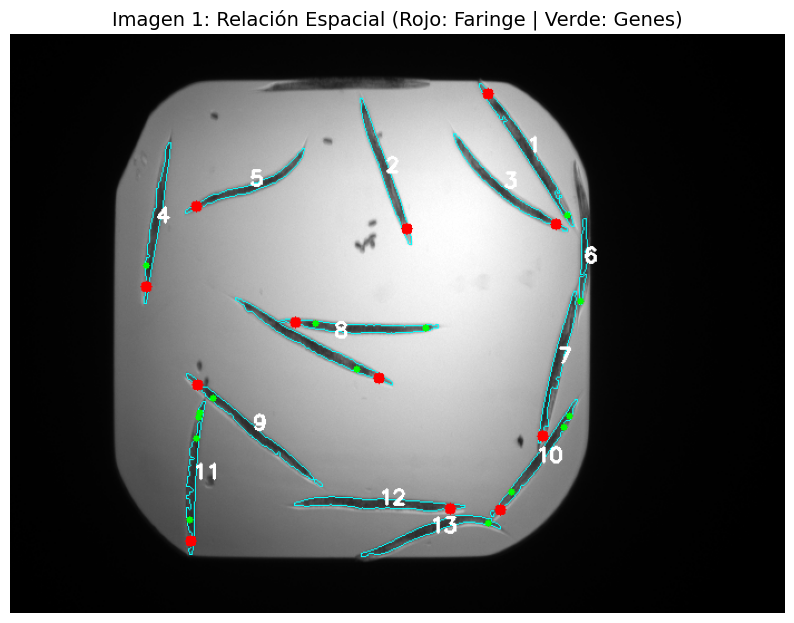


--- DETALLE DE RESULTADOS: IMAGEN 1 ---
Individuo 1 -> {Genes (1): [(500, 163)], Faringe (1): [(429, 54)]}
Individuo 2 -> {Genes (0): [], Faringe (1): [(356, 175)]}
Individuo 3 -> {Genes (0): [], Faringe (1): [(490, 171)]}
Individuo 4 -> {Genes (1): [(122, 208)], Faringe (1): [(122, 227)]}
Individuo 5 -> {Genes (0): [], Faringe (1): [(167, 155)]}
Individuo 6 -> {Genes (1): [(512, 240)], Faringe (0): []}
Individuo 7 -> {Genes (0): [], Faringe (1): [(478, 361)]}
Individuo 8 -> {Genes (3): [(274, 260), (373, 264), (311, 301)], Faringe (2): [(256, 259), (331, 309)]}
Individuo 9 -> {Genes (1): [(182, 327)], Faringe (1): [(168, 315)]}
Individuo 10 -> {Genes (3): [(502, 343), (497, 353), (450, 411)], Faringe (1): [(440, 427)]}
Individuo 11 -> {Genes (4): [(170, 340), (169, 344), (167, 363), (161, 436)], Faringe (1): [(162, 455)]}
Individuo 12 -> {Genes (0): [], Faringe (1): [(395, 426)]}
Individuo 13 -> {Genes (1): [(429, 439)], Faringe (0): []}
----------------------------------------------

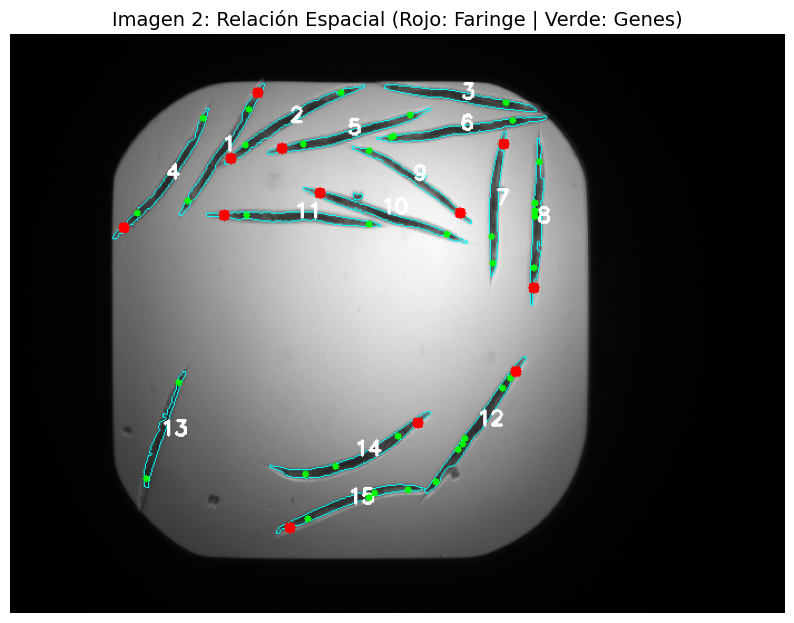


--- DETALLE DE RESULTADOS: IMAGEN 2 ---
Individuo 1 -> {Genes (2): [(214, 68), (159, 150)], Faringe (1): [(222, 53)]}
Individuo 2 -> {Genes (2): [(297, 53), (211, 100)], Faringe (1): [(198, 112)]}
Individuo 3 -> {Genes (1): [(445, 62)], Faringe (0): []}
Individuo 4 -> {Genes (2): [(173, 76), (114, 161)], Faringe (1): [(102, 174)]}
Individuo 5 -> {Genes (2): [(359, 73), (263, 99)], Faringe (1): [(244, 103)]}
Individuo 6 -> {Genes (3): [(451, 78), (342, 93), (344, 92)], Faringe (0): []}
Individuo 7 -> {Genes (2): [(432, 182), (433, 206)], Faringe (1): [(443, 99)]}
Individuo 8 -> {Genes (5): [(475, 115), (471, 152), (471, 159), (471, 164), (470, 210)], Faringe (1): [(470, 228)]}
Individuo 9 -> {Genes (1): [(322, 105)], Faringe (1): [(404, 161)]}
Individuo 10 -> {Genes (1): [(392, 180)], Faringe (1): [(278, 143)]}
Individuo 11 -> {Genes (2): [(212, 163), (322, 171)], Faringe (1): [(192, 163)]}
Individuo 12 -> {Genes (6): [(449, 309), (442, 318), (408, 363), (406, 368), (402, 373), (382, 4

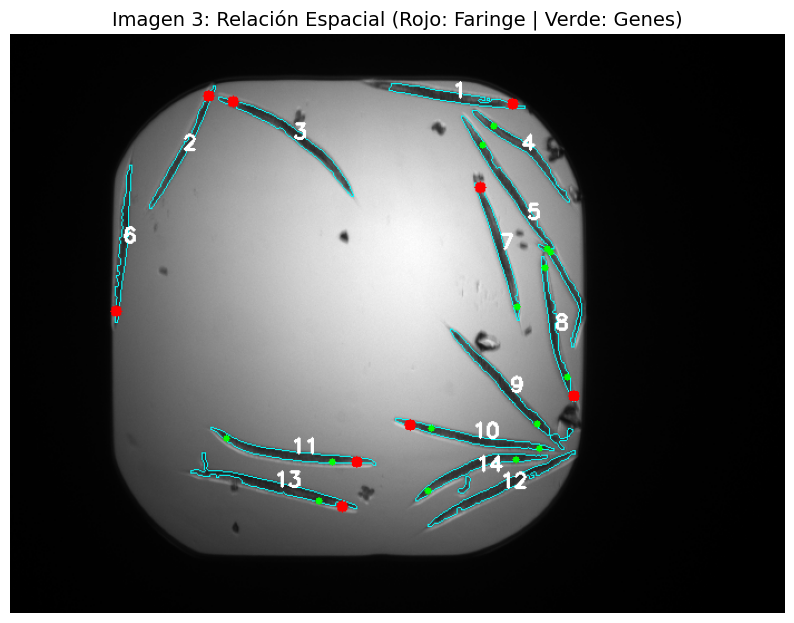


--- DETALLE DE RESULTADOS: IMAGEN 3 ---
Individuo 1 -> {Genes (0): [], Faringe (1): [(451, 63)]}
Individuo 2 -> {Genes (0): [], Faringe (1): [(178, 56)]}
Individuo 3 -> {Genes (0): [], Faringe (1): [(200, 61)]}
Individuo 4 -> {Genes (1): [(434, 83)], Faringe (0): []}
Individuo 5 -> {Genes (3): [(424, 100), (482, 193), (485, 196)], Faringe (0): []}
Individuo 6 -> {Genes (0): [], Faringe (1): [(95, 249)]}
Individuo 7 -> {Genes (1): [(455, 245)], Faringe (1): [(422, 138)]}
Individuo 8 -> {Genes (2): [(480, 210), (500, 308)], Faringe (1): [(506, 325)]}
Individuo 9 -> {Genes (1): [(473, 350)], Faringe (0): []}
Individuo 10 -> {Genes (2): [(378, 354), (475, 372)], Faringe (1): [(359, 351)]}
Individuo 11 -> {Genes (2): [(194, 363), (289, 384)], Faringe (1): [(311, 384)]}
Individuo 12 -> {Genes (0): [], Faringe (0): []}
Individuo 13 -> {Genes (1): [(277, 419)], Faringe (1): [(298, 424)]}
Individuo 14 -> {Genes (2): [(454, 382), (375, 410)], Faringe (0): []}
-----------------------------------

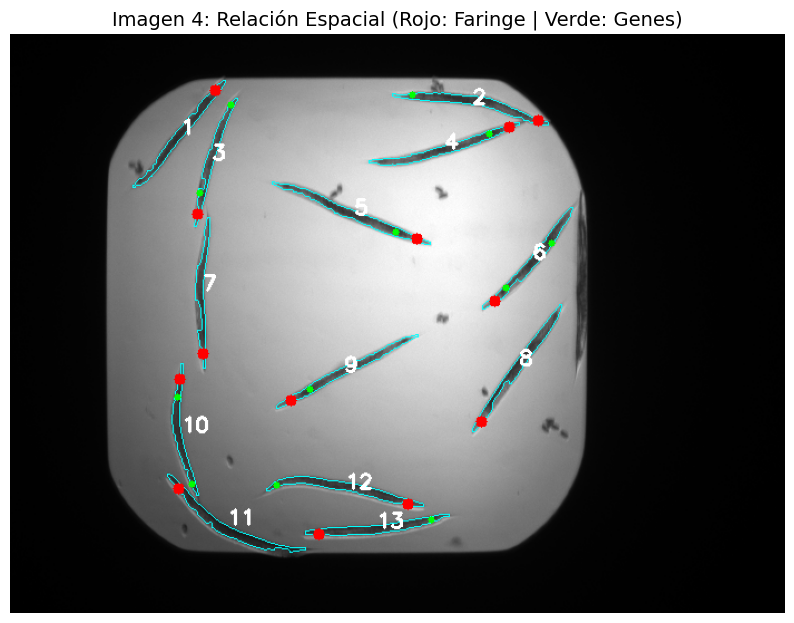


--- DETALLE DE RESULTADOS: IMAGEN 4 ---
Individuo 1 -> {Genes (0): [], Faringe (1): [(184, 51)]}
Individuo 2 -> {Genes (1): [(361, 55)], Faringe (1): [(474, 78)]}
Individuo 3 -> {Genes (2): [(198, 64), (170, 143)], Faringe (1): [(168, 162)]}
Individuo 4 -> {Genes (1): [(430, 90)], Faringe (1): [(448, 84)]}
Individuo 5 -> {Genes (1): [(346, 178)], Faringe (1): [(365, 184)]}
Individuo 6 -> {Genes (2): [(486, 188), (445, 228)], Faringe (1): [(435, 240)]}
Individuo 7 -> {Genes (0): [], Faringe (1): [(173, 287)]}
Individuo 8 -> {Genes (0): [], Faringe (1): [(423, 348)]}
Individuo 9 -> {Genes (1): [(269, 319)], Faringe (1): [(252, 329)]}
Individuo 10 -> {Genes (2): [(150, 326), (163, 404)], Faringe (1): [(152, 310)]}
Individuo 11 -> {Genes (0): [], Faringe (1): [(151, 408)]}
Individuo 12 -> {Genes (1): [(239, 405)], Faringe (1): [(357, 422)]}
Individuo 13 -> {Genes (1): [(378, 436)], Faringe (1): [(277, 449)]}
----------------------------------------------------------------------


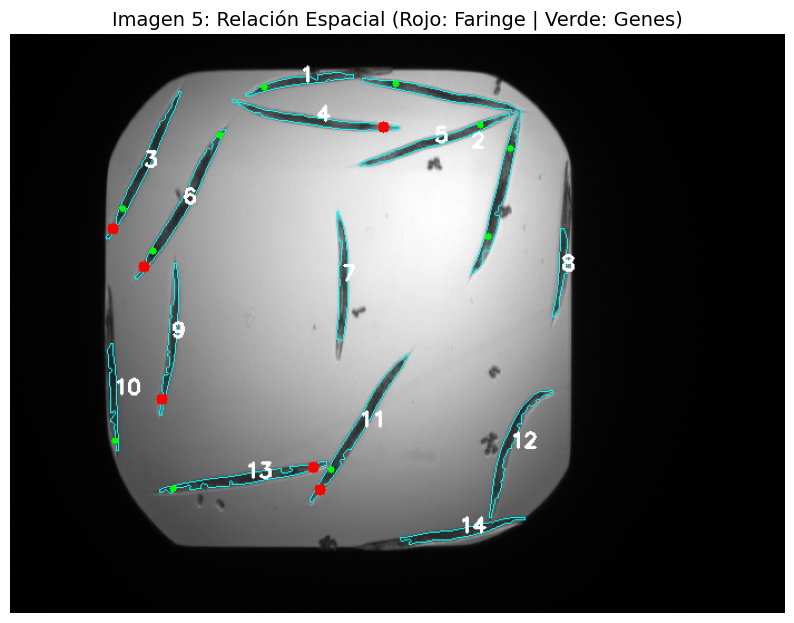


--- DETALLE DE RESULTADOS: IMAGEN 5 ---
Individuo 1 -> {Genes (1): [(228, 48)], Faringe (0): []}
Individuo 2 -> {Genes (3): [(346, 45), (449, 103), (429, 182)], Faringe (0): []}
Individuo 3 -> {Genes (1): [(101, 157)], Faringe (1): [(92, 175)]}
Individuo 4 -> {Genes (0): [], Faringe (1): [(335, 84)]}
Individuo 5 -> {Genes (1): [(422, 82)], Faringe (0): []}
Individuo 6 -> {Genes (2): [(188, 91), (128, 195)], Faringe (1): [(120, 209)]}
Individuo 7 -> {Genes (0): [], Faringe (0): []}
Individuo 8 -> {Genes (0): [], Faringe (0): []}
Individuo 9 -> {Genes (0): [], Faringe (1): [(136, 328)]}
Individuo 10 -> {Genes (1): [(94, 365)], Faringe (0): []}
Individuo 11 -> {Genes (1): [(288, 391)], Faringe (1): [(278, 409)]}
Individuo 12 -> {Genes (0): [], Faringe (0): []}
Individuo 13 -> {Genes (1): [(146, 408)], Faringe (1): [(272, 389)]}
Individuo 14 -> {Genes (0): [], Faringe (0): []}
----------------------------------------------------------------------


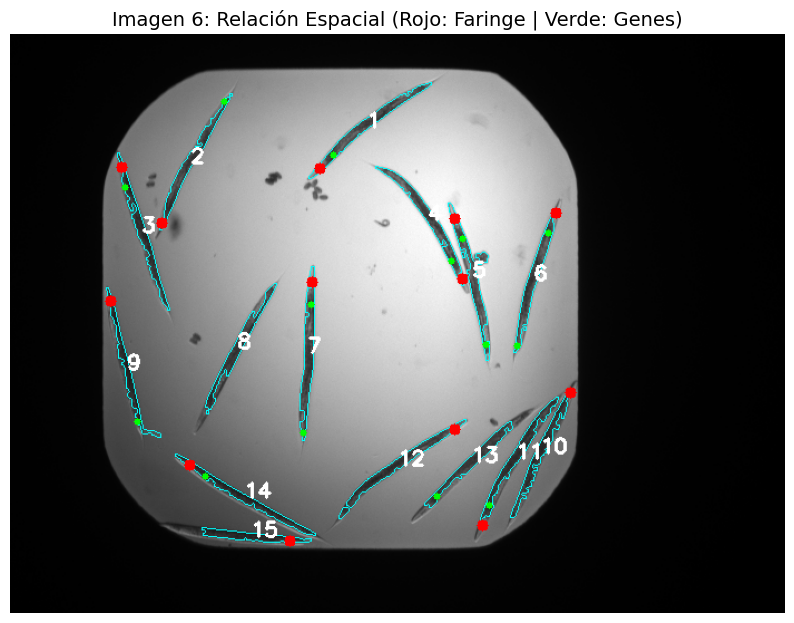


--- DETALLE DE RESULTADOS: IMAGEN 6 ---
Individuo 1 -> {Genes (1): [(290, 109)], Faringe (1): [(278, 121)]}
Individuo 2 -> {Genes (1): [(192, 61)], Faringe (1): [(136, 170)]}
Individuo 3 -> {Genes (1): [(103, 138)], Faringe (1): [(100, 120)]}
Individuo 4 -> {Genes (1): [(396, 204)], Faringe (1): [(406, 220)]}
Individuo 5 -> {Genes (2): [(406, 184), (427, 279)], Faringe (1): [(399, 166)]}
Individuo 6 -> {Genes (2): [(483, 179), (455, 280)], Faringe (1): [(490, 161)]}
Individuo 7 -> {Genes (2): [(270, 243), (263, 358)], Faringe (1): [(271, 223)]}
Individuo 8 -> {Genes (0): [], Faringe (0): []}
Individuo 9 -> {Genes (1): [(114, 348)], Faringe (1): [(90, 240)]}
Individuo 10 -> {Genes (0): [], Faringe (1): [(503, 322)]}
Individuo 11 -> {Genes (1): [(430, 423)], Faringe (1): [(424, 441)]}
Individuo 12 -> {Genes (0): [], Faringe (1): [(399, 355)]}
Individuo 13 -> {Genes (1): [(383, 415)], Faringe (0): []}
Individuo 14 -> {Genes (1): [(175, 397)], Faringe (1): [(161, 387)]}
Individuo 15 -> {G

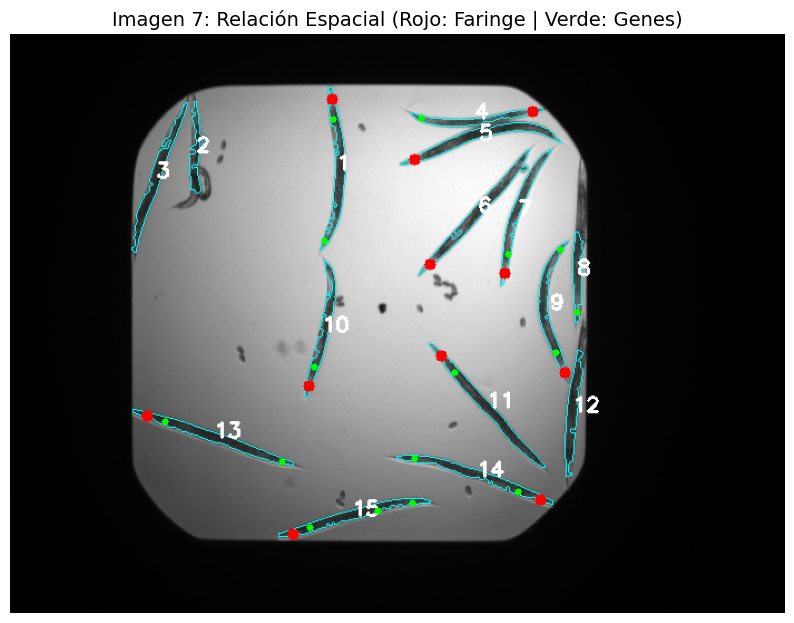


--- DETALLE DE RESULTADOS: IMAGEN 7 ---
Individuo 1 -> {Genes (2): [(290, 77), (282, 186)], Faringe (1): [(289, 59)]}
Individuo 2 -> {Genes (0): [], Faringe (0): []}
Individuo 3 -> {Genes (0): [], Faringe (0): []}
Individuo 4 -> {Genes (1): [(369, 76)], Faringe (1): [(469, 70)]}
Individuo 5 -> {Genes (0): [], Faringe (1): [(363, 113)]}
Individuo 6 -> {Genes (0): [], Faringe (1): [(377, 207)]}
Individuo 7 -> {Genes (1): [(447, 198)], Faringe (1): [(444, 215)]}
Individuo 8 -> {Genes (1): [(509, 250)], Faringe (0): []}
Individuo 9 -> {Genes (2): [(494, 194), (490, 286)], Faringe (1): [(498, 304)]}
Individuo 10 -> {Genes (1): [(273, 299)], Faringe (1): [(268, 316)]}
Individuo 11 -> {Genes (1): [(399, 304)], Faringe (1): [(387, 289)]}
Individuo 12 -> {Genes (0): [], Faringe (0): []}
Individuo 13 -> {Genes (2): [(139, 348), (244, 384)], Faringe (1): [(123, 343)]}
Individuo 14 -> {Genes (2): [(363, 381), (456, 411)], Faringe (1): [(476, 418)]}
Individuo 15 -> {Genes (3): [(361, 421), (330, 4

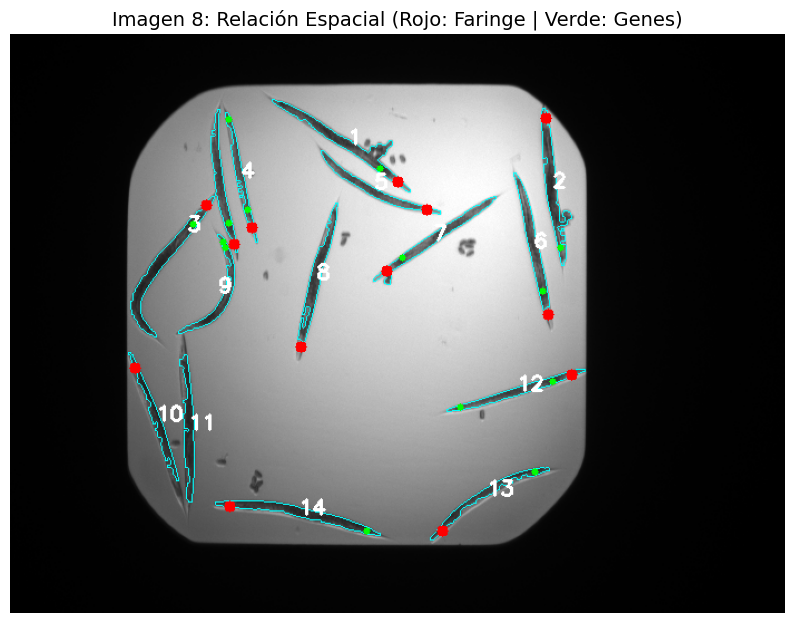


--- DETALLE DE RESULTADOS: IMAGEN 8 ---
Individuo 1 -> {Genes (1): [(332, 121)], Faringe (1): [(348, 133)]}
Individuo 2 -> {Genes (1): [(494, 192)], Faringe (1): [(481, 76)]}
Individuo 3 -> {Genes (2): [(196, 170), (164, 171)], Faringe (2): [(176, 154), (201, 189)]}
Individuo 4 -> {Genes (2): [(196, 77), (213, 158)], Faringe (1): [(217, 174)]}
Individuo 5 -> {Genes (0): [], Faringe (1): [(374, 158)]}
Individuo 6 -> {Genes (1): [(478, 231)], Faringe (1): [(483, 252)]}
Individuo 7 -> {Genes (1): [(352, 201)], Faringe (1): [(338, 213)]}
Individuo 8 -> {Genes (0): [], Faringe (1): [(261, 281)]}
Individuo 9 -> {Genes (2): [(191, 187), (193, 192)], Faringe (0): []}
Individuo 10 -> {Genes (0): [], Faringe (1): [(112, 300)]}
Individuo 11 -> {Genes (0): [], Faringe (0): []}
Individuo 12 -> {Genes (2): [(487, 312), (404, 335)], Faringe (1): [(504, 306)]}
Individuo 13 -> {Genes (1): [(471, 393)], Faringe (1): [(388, 446)]}
Individuo 14 -> {Genes (1): [(320, 446)], Faringe (1): [(197, 424)]}
----

In [10]:
# INICIALIZACIÓN DE ESTRUCTURAS GLOBALES
# Base de datos que guardará toda la información
asociacion_final = []
# Lista auxiliar para guardar las imágenes ya dibujadas para la visualización final
imagenes_visualizacion = [] 

# FASE 1: PROCESAMIENTO Y GENERACIÓN DE LA ESTRUCTURA DE DATOS
for idx, img_set in enumerate(imagenes_norm):
    
    # Recuperación de los datos necesarios de esta imagen específica
    img_fondo = img_set[:,:,0] # Canal w1 para usar de fondo
    gusanos_imagen = resultados_por_imagen[idx] # Estructuras de los nematodos
    genes_imagen = lista_centroides_global[idx]    # Coordenadas de los genes
    faringes_imagen = lista_faringes_global[idx]  # Coordenadas de las faringes
    
    # Preparación del lienzo para dibujar (convertimos el fondo w1 a color RGB)
    vis_final = cv2.cvtColor(img_fondo.astype(np.uint8), cv2.COLOR_GRAY2RGB)
    
    # Diccionario para guardar los resultados específicos de esta imagen
    relacion_imagen = {}

    # Iteramos sobre cada individuo detectado en la imagen
    for gus in gusanos_imagen:
        id_g = gus["id"]
        mask = gus["mask"]     # Máscara binaria del cuerpo del gusano
        centro = gus["centro"] # Centroide del cuerpo
        contornos = gus["contorno"] # Contorno del cuerpo
        
        # --- A. Asociación de genes (w2) ---
        genes_asociados = []
        for gx, gy in genes_imagen:
            # Comprobamos espacialmente si el gen está dentro del cuerpo
            if mask[gy, gx] > 0:
                # gx y gy ya llegaron como enteros limpios de pasos anteriores
                genes_asociados.append((gx, gy))
        
        # --- B. Asociación de faringes (w3) ---
        faringes_asociadas = []
        for fx, fy in faringes_imagen:
            # Comprobamos espacialmente si la faringe está dentro del cuerpo
            if mask[fy, fx] > 0:
                faringes_asociadas.append((fx, fy))
        
        # --- C. Estructura de datos final por individuo
        relacion_imagen[f"Individuo {id_g}"] = {
            "n_genes": len(genes_asociados),
            "coords_genes": genes_asociados,
            "n_faringe": len(faringes_asociadas),
            "coords_faringe": faringes_asociadas
        }
        
        # --- D. Dibujo para la validación visual ---
        # Contorno (Cian)
        cv2.drawContours(vis_final, contornos, -1, (0, 255, 255), 1)
        # ID en el centroide (Blanco)
        cv2.putText(vis_final, str(id_g), (centro[0], centro[1]), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
        
        # Genes Detectados (Círculos sólidos Verdes, Radio 3)
        for gx, gy in genes_asociados:
            cv2.circle(vis_final, (gx, gy), 3, (0, 255, 0), -1)
            
        # Faringes Detectadas (Círculos sólidos Rojos, Radio 5)
        for fx, fy in faringes_asociadas:
            cv2.circle(vis_final, (fx, fy), 5, (255, 0, 0), -1)
    
    # Guardamos el diccionario de datos y la imagen final dibujada
    asociacion_final.append(relacion_imagen)
    imagenes_visualizacion.append(vis_final) 


# FASE 2: VISUALIZACIÓN Y SALIDA DEL INFORME FINAL
# Recuperamos la información guardada secuencialmente para mostrarla.

print("\n" + "="*80)
print("INFORME FINAL DE ASOCIACIÓN POR IMAGEN")
print("="*80)

for idx in range(len(imagenes_visualizacion)):
    # 1. Mostrar la imagen correspondiente
    plt.figure(figsize=(10, 8))
    plt.imshow(imagenes_visualizacion[idx])
    plt.title(f"Imagen {idx + 1}: Relación Espacial (Rojo: Faringe | Verde: Genes)", fontsize=14)
    plt.axis('off')
    plt.show()

    # 2. Mostrar el informe de datos debajo de cada imagen 
    datos_esta_imagen = asociacion_final[idx]
    
    print(f"\n--- DETALLE DE RESULTADOS: IMAGEN {idx + 1} ---")
    
    # Si la imagen no tiene gusanos detectados
    if not datos_esta_imagen:
        print("No se detectaron individuos.")
    else:
        for nombre_ind, info in datos_esta_imagen.items():
            print(f"{nombre_ind} -> {{Genes ({info['n_genes']}): {info['coords_genes']}, Faringe ({info['n_faringe']}): {info['coords_faringe']}}}")
            
    print("-" * 70)

### 6. Análisis de los resultados de la asociación multicanal
   
- Faringes (Canal w3): La prevalencia de una faringe por individuo valida la eficacia de la dilatación morfológica para fusionar los bulbos. Los casos de dos o ninguna faringe detectada se deben seguramente a dos factores:
    - Inexactitud en la segmentación del canal w1: debida a la lógica de asociación por máscara, los casos donde nematodos muy próximos se identifican como único individuo afectarán a la asociación de sus estructuras internas.
    
    - Limitaciones de la dilatación: Como se anticipó, la fusión accidental de faringes distintas en una sola masa desplazó el centroide resultante fuera de los límites de las máscaras corporales, impidiendo su asociación a ningún ejemplar. 

- Gusanos (Canal w1): Se ha logrado una segmentación robusta de la población. Las omisiones se deben a individuos situados en los márgenes de las imágenes o demasiado próximos a otros, de tal manera que el algoritmo los procesó como un único objeto.

- Genes (Canal w2): El sistema detectó un rango de expresión de 0 a 6 genes por individuo. La mayoría de la población presenta entre 0 y 3 focos. 
